<div style="text-align: left;">

# Olist Sales and Customer Behavior Analysis

Raw data is read from the `Olist-data/` folder. Required libraries: `pandas`, `numpy`, `matplotlib`, `seaborn`, `packaging` (the Persian edition also uses `arabic-reshaper` and `python-bidi`). Cells run from the project root. The delivered goods value covers item prices only and excludes freight.

</div>

# 1. Project Introduction

In this project we act as a Data Analyst for an e-commerce platform.

The data belongs to Olist, a Brazilian e-commerce platform. The platform lets multiple sellers offer their products to customers across Brazil through online storefronts.

Over the platform's lifetime a large volume of information has been recorded about orders, customers, products, sellers, payments, shipments and customer reviews.

Data by itself has little business value. Real value is created when we can use the data to answer business questions.

In this project we use real data to move from raw data to information, patterns and finally business insight.

## Project Goals

Imagine we have just joined the Olist data team and the company's managers have asked us to examine the available data and present an overall picture of the business.

By the end of the project we must be able to explain to management:

- What state is the business in?
- How do customers behave?
- Which parts perform well?
- Which parts may need further investigation?

### Skills Used

- Data cleaning and preparation
- Working with several `DataFrame`s
- Joining tables
- Using `groupby` and aggregation
- Working with time series data
- Deriving business KPIs
- Analyzing customer behavior
- Using `Pandas` for analysis
- Choosing appropriate charts
- Plotting with `Matplotlib` and `Seaborn`
- Interpreting charts
- Extracting business insight

---



<div style="text-align: left;">

### Four Management Questions

- Business status: orders and delivered goods value are compared across same-month periods.
- Customer behavior: geographic concentration and the second-order rate under an equal observation window.
- Strengths: the share of early deliveries and of high scores is the evaluation basis.
- Areas to investigate: the rising late rate and the review-score gap are the priorities.

</div>

# 2. Data Introduction

Unlike many simple data-analysis exercises, this project's dataset is not a single `CSV` file. The business information is stored in several tables, each describing one part of the store's activity.

## Tables in the Dataset

| Table | Information |
| :---- | :---------- |
| Orders | order status, purchase, shipping and delivery timestamps |
| Customers | customer information and location |
| Products | product information and category |
| Order items | purchased product, seller and price |
| Payments | payment method, amount and installments |
| Sellers | seller information and location |
| Reviews | score left by the customer after the purchase |

To answer most project questions, several tables must be combined through their shared keys.

## Dataset Structure

The figure below should show the dataset structure and the relationships between tables.

**Path of the figure in the project:**

`Olist-data/olist_database_schema.png`

![Olist dataset schema and table relationships](Olist-data/olist_database_schema.png)

_Figure 1 - Structure of the Olist dataset tables and their relationships_

---



<div style="text-align: left;">

### Data Structure

Figure 2.1 shows how the tables relate and through which keys. The translation table connects to products through `product_category_name`. The geolocation zip-code prefix is not unique, so joining it directly to orders can multiply row counts several times over.

</div>
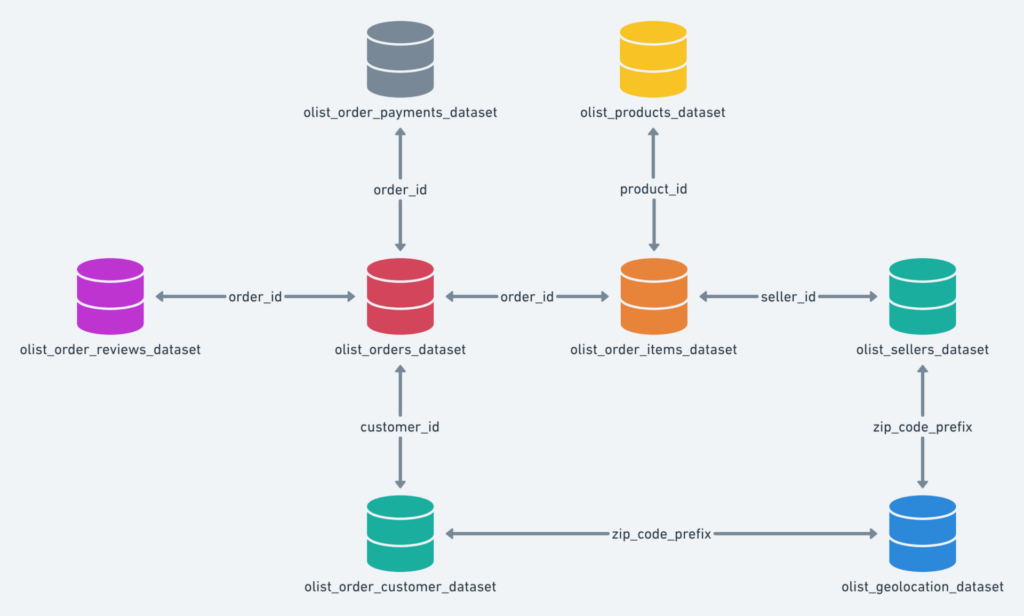

In [1]:
%matplotlib inline
from pathlib import Path
import re
from html import escape
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from packaging.version import Version
from IPython.display import display


class CaptionedTable:
    def __init__(self, caption, frame):
        self.caption, self.frame = caption, frame

    def __repr__(self):
        return self.caption + "\n" + self.frame.to_string()

    def _repr_html_(self):
        table = self.frame._repr_html_()
        return '<div style="text-align:left"><p><b>' + escape(self.caption) + '</b></p>' + table + '</div>'


def show_table(number, title, frame, formats=None, labels=None, sample=None, period=None):
    out = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()
    assert out.shape[1] + out.index.nlevels <= 6, (number, out.shape)
    formats, labels = formats or {}, labels or {}
    for col in out.columns:
        kind = formats.get(col, '')
        def fmt(v):
            if pd.isna(v): return '-'
            if kind == 'brl': return f'{(0.0 if abs(v) < 0.005 else v):,.2f} BRL'
            if kind == 'pct': return f'{v:,.1f}%'
            if kind == 'score': return f'{v:.2f}'
            if kind == 'pp': return f'{v:.1f}'
            if kind == 'decimal': return f'{v:,.2f}'
            if isinstance(v, (bool, np.bool_)): return str(bool(v))
            if isinstance(v, (int, np.integer)): return f'{v:,}'
            if isinstance(v, (float, np.floating)): return f'{v:,.2f}'
            return str(v)
        out[col] = out[col].map(fmt)
    out = out.rename(columns={key: SHORT_LABELS.get(value, value) for key, value in labels.items()})
    assert out.columns.is_unique, number
    caption = f'Table {number} | {title} | {sample} | {period or ORDER_PERIOD}'
    display(CaptionedTable(caption, out))


def heading(ax, number, title, period=None):
    title = title.replace(', full data period', '').replace(', full period', '')
    ax.set_title(f'Chart {number} | {title}, {period or ORDER_PERIOD}', fontsize=10, pad=12)


def axes_labels(ax, x, y):
    ax.set_xlabel(x)
    ax.set_ylabel(y)


def complete():
    plt.tight_layout()
    plt.show()


sns.set_theme(style='whitegrid', font='DejaVu Sans', rc={
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': '#e2ebeb', 'axes.edgecolor': '#bfd0d1',
    'axes.unicode_minus': False, 'figure.dpi': 110,
})
pd.set_option('display.max_rows', 150)
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 180)
DATA = Path('Olist-data')
files = {
    'orders': 'olist_orders_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
missing = [str(DATA / f) for f in files.values() if not (DATA / f).is_file()]
if missing:
    raise FileNotFoundError('Missing raw input files: ' + ', '.join(missing))
zip_types = {
    'customers': {'customer_zip_code_prefix': 'string'},
    'sellers': {'seller_zip_code_prefix': 'string'},
    'geolocation': {'geolocation_zip_code_prefix': 'string'},
}
raw = {name: pd.read_csv(DATA / path, dtype=zip_types.get(name), encoding='utf-8-sig')
       for name, path in files.items()}
START = pd.Timestamp('2017-01-01')
END = pd.Timestamp('2018-09-01')
MIN_REVIEWS = 30
MIN_STATE = 100
SCORE_GAP = 0.10
WINDOW_DAYS = 90
FIRST_YEAR = START.year
LAST_YEAR = (END - pd.Timedelta(days=1)).year
TREND_PERIOD = f"{START:%Y-%m} to {(END - pd.Timedelta(days=1)):%Y-%m}"
ORDER_DATES = pd.to_datetime(raw['orders'].order_purchase_timestamp, errors='coerce')
ORDER_PERIOD = f"{ORDER_DATES.min():%Y-%m-%d} to {ORDER_DATES.max():%Y-%m-%d}"
REVIEW_DATES = pd.to_datetime(raw['reviews'].review_creation_date, errors='coerce')
REVIEW_PERIOD = f"{REVIEW_DATES.min():%Y-%m-%d} to {REVIEW_DATES.max():%Y-%m-%d}"
COHORT_END = (END - pd.Timedelta(days=WINDOW_DAYS)).replace(day=1)
COHORT_PERIOD = f"{START:%Y-%m} to {(COHORT_END - pd.Timedelta(days=1)):%Y-%m}"
SHORT_LABELS = {
    'Delivered goods value, BRL': 'Delivered value',
    'Delivered goods value': 'Delivered value', 'Goods value, all statuses': 'Value, all statuses',
    'Mean review score': 'Review score', 'Mean score per order': 'Order score',
    'Customers with observation window': 'Eligible customers', 'Customers with second order': 'Second order',
    'Sellers among top-10 sellers': 'Top-10 sellers', 'In candidate list': 'Candidate',
    'Paid orders without items': 'Paid, no items', 'Orders without registered items': 'No-item orders',
    'Value-vs-items rank difference': 'Rank diff', 'Early-vs-late score gap': 'Score gap',
    'Mean installments': 'Mean inst.', 'Multi-transaction orders': 'Multi-txn',
    'Gap vs no-delay group': 'Score gap', 'Gap vs review baseline': 'Score gap',
    'Change vs first period': 'Change %', 'Comparable orders': 'Comparable orders',
    'With items, all statuses': 'With items', 'With delivered items': 'Delivered',
    'Strict candidate count': 'Strict candidates', 'Broad candidate count': 'Broad candidates',
    'Eligible-group value threshold': 'Eligible threshold', 'All-delivered-sellers value threshold': 'Broad threshold',
}


# 3. Knowing the Data

Before the analysis starts, the data at hand must be well understood.

## Questions and Activities

1. Which files and tables exist in the dataset?
2. How many rows and columns does each table have?
3. What does one row of each table represent?
4. Identify the key columns of each table.
5. Check the `dtype` of the columns. Does any data type look unsuitable?
6. Which columns can be used to relate the tables?
7. Is there duplicate data in the tables?
8. Check the `Missing Values` in each table.
9. Compute the percentage of missing values per column.

## Expected Output

At the end of this section, explain the overall data structure and the relationships between tables in a few lines.

---



### 3.1. Table Size and Row Grain

Table 3.1 shows the size, the grain of each row and the join keys. Table 3.2 reports duplicates and missing cells without removing any row.



In [2]:
grains = {
    'orders': ('Orders', 'order_id'),
    'customers': ('Customer per order', 'customer_id'),
    'items': ('Item per order', 'order_id + order_item_id'),
    'payments': ('Payment transaction', 'order_id + payment_sequential'),
    'reviews': ('Review record', 'order_id / review_id'),
    'products': ('Product', 'product_id'),
    'sellers': ('Seller', 'seller_id'),
    'geolocation': ('Location / zip record', 'geolocation_zip_code_prefix'),
    'translation': ('Category key translation', 'product_category_name'),
}
inventory = pd.DataFrame([
    {'table_key': name, 'file': files[name], 'rows': len(df), 'columns': df.shape[1],
     'grain': grains[name][0], 'key': grains[name][1]}
    for name, df in raw.items()
]).set_index('table_key')
show_table('3.1', 'Size and keys of raw tables', inventory, labels={
    'file':'File', 'rows':'Rows', 'columns':'Columns', 'grain':'Row grain', 'key':'Key'}, sample=f'{len(raw):,} raw tables', period=ORDER_PERIOD)
quality = pd.DataFrame([
    {'table_key': name, 'duplicates': int(df.duplicated().sum()),
     'missing_cells': int(df.isna().sum().sum())}
    for name, df in raw.items()
]).set_index('table_key')
show_table('3.2', 'Full-row duplicates and missing cells', quality,
      labels={'duplicates':'Full-row duplicates', 'missing_cells':'Missing cells'}, sample=f'{len(raw):,} raw tables', period=ORDER_PERIOD)

,File,Rows,Columns,Row grain,Key
table_key,,,,,
orders,olist_orders_dataset.csv,"99,441",8,Orders,order_id
customers,olist_customers_dataset.csv,"99,441",5,Customer per order,customer_id
items,olist_order_items_dataset.csv,"112,650",7,Item per order,order_id + order_item_id
payments,olist_order_payments_dataset.csv,"103,886",5,Payment transaction,order_id + payment_sequential
reviews,olist_order_reviews_dataset.csv,"99,224",7,Review record,order_id / review_id
products,olist_products_dataset.csv,"32,951",9,Product,product_id
sellers,olist_sellers_dataset.csv,"3,095",4,Seller,seller_id
geolocation,olist_geolocation_dataset.csv,"1,000,163",5,Location / zip record,geolocation_zip_code_prefix
translation,product_category_name_translation.csv,71,2,Category key translation,product_category_name


,Full-row duplicates,Missing cells
table_key,,
orders,0,"4,908"
customers,0,0
items,0,0
payments,0,0
reviews,0,"145,903"
products,0,"2,448"
sellers,0,0
geolocation,"261,831",0
translation,0,0


### 3.2. Data Types and Missing Values

Table 3.3 shows the dtype, the count and the share of missing values per column. Table 3.4 separates the time columns that need conversion. Zip-code prefixes are read as strings so leading zeros survive.

Note: the `Read dtype` display depends on the pandas version (`str` under pandas 3.x, `object` under pandas 2.x). The counts and percentages are identical.



In [3]:
profiles = []
for name, df in raw.items():
    for col in df.columns:
        profiles.append({'table_key':name, 'column':col, 'dtype':str(df[col].dtype),
                         'missing':int(df[col].isna().sum()),
                         'missing_pct':df[col].isna().mean()*100})
column_profile = pd.DataFrame(profiles).set_index(['table_key', 'column'])
show_table('3.3', 'Column dtypes and missing coverage', column_profile, {'missing_pct':'pct'},
      {'dtype':'Read dtype', 'missing':'Missing', 'missing_pct':'Missing %'}, sample=f'{len(column_profile):,} columns', period=ORDER_PERIOD)
time_cols = {
    'orders': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
               'order_delivered_customer_date', 'order_estimated_delivery_date'],
    'items': ['shipping_limit_date'],
    'reviews': ['review_creation_date', 'review_answer_timestamp'],
}
time_profile = pd.DataFrame([
    {'table_key': name, 'column': col, 'raw_dtype': str(raw[name][col].dtype),
     'invalid': int((pd.to_datetime(raw[name][col], errors='coerce').isna() & raw[name][col].notna()).sum())}
    for name, cols in time_cols.items() for col in cols
]).set_index(['table_key', 'column'])
show_table('3.4', 'Time columns and unconvertible values', time_profile,
      labels={'raw_dtype':'Raw dtype', 'invalid':'Unconvertible'}, sample=f'{len(time_profile):,} time columns', period=ORDER_PERIOD)

Table 3.3 | Column dtypes and missing coverage | 52 columns | 2016-09-04 to 2018-10-17
                                          Read dtype Missing Missing %
table_key   column                                                    
orders      order_id                          object       0      0.0%
            customer_id                       object       0      0.0%
            order_status                      object       0      0.0%
            order_purchase_timestamp          object       0      0.0%
            order_approved_at                 object     160      0.2%
            order_delivered_carrier_date      object   1,783      1.8%
            order_delivered_customer_date     object   2,965      3.0%
            order_estimated_delivery_date     object       0      0.0%
customers   customer_id                       object       0      0.0%
            customer_unique_id                object       0      0.0%
            customer_zip_code_prefix          string       0      0.0%
            customer_city                     object       0      0.0%
            customer_state                    object       0      0.0%
items       order_id                          object       0      0.0%
            order_item_id                      int64       0      0.0%
            product_id                        object       0      0.0%
            seller_id                         object       0      0.0%
            shipping_limit_date               object       0      0.0%
            price                            float64       0      0.0%
            freight_value                    float64       0      0.0%
payments    order_id                          object       0      0.0%
            payment_sequential                 int64       0      0.0%
            payment_type                      object       0      0.0%
            payment_installments               int64       0      0.0%
            payment_value                    float64       0      0.0%
reviews     review_id                         object       0      0.0%
            order_id                          object       0      0.0%
            review_score                       int64       0      0.0%
            review_comment_title              object  87,656     88.3%
            review_comment_message            object  58,247     58.7%
            review_creation_date              object       0      0.0%
            review_answer_timestamp           object       0      0.0%
products    product_id                        object       0      0.0%
            product_category_name             object     610      1.9%
            product_name_lenght              float64     610      1.9%
            product_description_lenght       float64     610      1.9%
            product_photos_qty               float64     610      1.9%
            product_weight_g                 float64       2      0.0%
            product_length_cm                float64       2      0.0%
            product_height_cm                float64       2      0.0%
            product_width_cm                 float64       2      0.0%
sellers     seller_id                         object       0      0.0%
            seller_zip_code_prefix            string       0      0.0%
            seller_city                       object       0      0.0%
            seller_state                      object       0      0.0%
geolocation geolocation_zip_code_prefix       string       0      0.0%
            geolocation_lat                  float64       0      0.0%
            geolocation_lng                  float64       0      0.0%
            geolocation_city                  object       0      0.0%
            geolocation_state                 object       0      0.0%
translation product_category_name             object       0      0.0%
            product_category_name_english     object       0      0.0%

Table 3.4 | Time columns and unconvertible values | 8 time columns | 2016-09-04 to 2018-10-17
                                        Raw dtype Unconvertible
table_key column                                               
orders    order_purchase_timestamp         object             0
          order_approved_at                object             0
          order_delivered_carrier_date     object             0
          order_delivered_customer_date    object             0
          order_estimated_delivery_date    object             0
items     shipping_limit_date              object             0
reviews   review_creation_date             object             0
          review_answer_timestamp          object             0

### 3.3. Keys and Structure Summary

Table 3.5 shows key uniqueness. The order key links an order to its items, transactions and reviews; the customer key reaches the stable customer identity. One order can have several items, payments or reviews, so joining all tables without defining the unit of analysis inflates row counts.

The zip-code prefix is not unique in the geolocation table; for that reason it is not joined directly to orders. The products table connects to the translation table through the category key. In Table 3.4 the dates are read as strings, and converting them to a time type is required for durations and trends; a missing delivery date is not assumed to equal the estimated delivery date.



In [4]:
key_checks = pd.DataFrame([
    {'key':'orders.order_id', 'unique':raw['orders'].order_id.is_unique},
    {'key':'customers.customer_id', 'unique':raw['customers'].customer_id.is_unique},
    {'key':'items.order_id + order_item_id', 'unique':not raw['items'].duplicated(['order_id','order_item_id']).any()},
    {'key':'payments.order_id + payment_sequential', 'unique':not raw['payments'].duplicated(['order_id','payment_sequential']).any()},
    {'key':'reviews.review_id', 'unique':raw['reviews'].review_id.is_unique},
    {'key':'reviews.order_id', 'unique':raw['reviews'].order_id.is_unique},
    {'key':'geolocation.geolocation_zip_code_prefix', 'unique':raw['geolocation'].geolocation_zip_code_prefix.is_unique},
]).set_index('key')
show_table('3.5', 'Key uniqueness checks', key_checks, labels={'unique':'Key unique'}, sample=f'{len(key_checks):,} keys', period=ORDER_PERIOD)

,Key unique
key,
orders.order_id,True
customers.customer_id,True
items.order_id + order_item_id,True
payments.order_id + payment_sequential,True
reviews.review_id,False
reviews.order_id,False
geolocation.geolocation_zip_code_prefix,False


# 4. Data Cleaning and Preparation

Before the business analyses, prepare the data.

## Questions and Activities

1. What decision do you make for the observed `Missing Values`? Explain your reasoning.
2. Check duplicate records.
3. Fix the data types of the columns.
4. Convert date and time columns to `datetime`.
5. Check unusual or suspicious values.
6. If needed, create new columns, such as:

- order year
- order month
- order day (weekday)
- delivery duration
- delivery delay in days

## Expected Output

At the end of this section you should have clean `DataFrame`s ready for analysis.

---



### 4.1. Cleaning Decisions and Prepared Tables

Dates are converted to a time type. Orders, items and reviews are kept without dropping duplicate rows. Fully duplicated geolocation records are separated only inside the geo screening set. Duration and late-rate calculations use only valid dates and non-negative durations. Tables 4.1 and 4.2 show the exceptions and the decisions.



In [5]:
orders = raw['orders'].copy()
items = raw['items'].copy()
customers = raw['customers'].copy()
payments = raw['payments'].copy()
reviews = raw['reviews'].copy()
products = raw['products'].copy()
sellers = raw['sellers'].copy()
geo = raw['geolocation'].copy()
translation = raw['translation'].copy()
for name, columns in time_cols.items():
    df = {'orders':orders, 'items':items, 'reviews':reviews}[name]
    for col in columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')
orders['purchase_month'] = orders.order_purchase_timestamp.dt.to_period('M')
orders['purchase_year'] = orders.order_purchase_timestamp.dt.year
orders['purchase_weekday'] = orders.order_purchase_timestamp.dt.day_of_week
geo_unique = geo.drop_duplicates().copy()
geo_outside = (~geo.geolocation_lat.between(-34, 6) | ~geo.geolocation_lng.between(-74, -28))
order_customer = orders.merge(customers, on='customer_id', how='left', validate='one_to_one')
delivered_orders = orders.loc[orders.order_status.eq('delivered')].copy()
duration_orders = delivered_orders.dropna(subset=['order_purchase_timestamp', 'order_delivered_customer_date']).copy()
duration_orders['duration_days'] = (duration_orders.order_delivered_customer_date - duration_orders.order_purchase_timestamp).dt.total_seconds()/86400
duration_orders = duration_orders.loc[duration_orders.duration_days.ge(0)].copy()
delivery = duration_orders.dropna(subset=['order_estimated_delivery_date']).copy()
delivery['delay_days'] = (delivery.order_delivered_customer_date.dt.normalize() -
                          delivery.order_estimated_delivery_date.dt.normalize()).dt.days
delivery['delivery_group'] = np.select([delivery.delay_days.lt(0), delivery.delay_days.eq(0)],
                                       ['early', 'on_time'], default='late')
delivery['is_late'] = delivery.delay_days.gt(0)
all_items = items.merge(orders[['order_id','order_status','order_purchase_timestamp','purchase_month']],
                        on='order_id', how='left', validate='many_to_one')
all_items = all_items.merge(products[['product_id','product_category_name']],
                            on='product_id', how='left', validate='many_to_one')
all_items = all_items.merge(translation[['product_category_name','product_category_name_english']],
                            on='product_category_name', how='left', validate='many_to_one')
all_items['category'] = (all_items.product_category_name_english.fillna(all_items.product_category_name)
                         .fillna('unknown'))
del_items = all_items.loc[all_items.order_status.eq('delivered')].copy()
review_order = reviews.groupby('order_id').review_score.mean().rename('order_mean_score')
review_baseline = reviews.review_score.mean()
order_baseline = review_order.mean()
exception_table = pd.DataFrame([
    {'case':'delivered_without_date', 'count':int(delivered_orders.order_delivered_customer_date.isna().sum()),
     'decision':'Excluded from delivery analysis'},
    {'case':'other_status_with_delivery_date', 'count':int((~orders.order_status.eq('delivered') & orders.order_delivered_customer_date.notna()).sum()),
     'decision':'Kept, outside delivery analysis'},
    {'case':'not_defined', 'count':int(payments.payment_type.eq('not_defined').sum()),
     'decision':'Kept as registered transaction'},
]).set_index('case')
show_table('4.1', 'Statuses with delivery dates or unusual payment type', exception_table,
      labels={'count':'Count', 'decision':'Decision'}, sample=f'{len(orders):,} orders and {len(payments):,} transactions', period=ORDER_PERIOD)
quality_decisions = pd.DataFrame([
    {'check':'geolocation_full_duplicates', 'count':int(geo.duplicated().sum()), 'decision':'Dropped in geo screening set'},
    {'check':'geolocation_outside_bounding_box', 'count':int(geo_outside.sum()), 'decision':'Kept raw, screened separately'},
    {'check':'delivery_over_100_days', 'count':int(duration_orders.duration_days.gt(100).sum()), 'decision':'Kept, plausible far outlier'},
    {'check':'delivery_negative_days', 'count':int(((delivered_orders.order_delivered_customer_date-delivered_orders.order_purchase_timestamp).dt.total_seconds()<0).sum()), 'decision':'Excluded from duration analysis'},
    {'check':'product_weight_zero', 'count':int(products.product_weight_g.eq(0).sum()), 'decision':'Kept, outside valid-weight analysis'},
    {'check':'item_price_zero', 'count':int(items.price.eq(0).sum()), 'decision':'Kept and reported'},
    {'check':'freight_value_zero', 'count':int(items.freight_value.eq(0).sum()), 'decision':'Kept, may be free shipping'},
]).set_index('check')
show_table('4.2', 'Duplicates and unusual values', quality_decisions,
      labels={'count':'Count', 'decision':'Decision'}, sample=f'{len(quality_decisions):,} quality checks', period=ORDER_PERIOD)

,Count,Decision
case,,
delivered_without_date,8,Excluded from delivery analysis
other_status_with_delivery_date,6,"Kept, outside delivery analysis"
not_defined,3,Kept as registered transaction


,Count,Decision
check,,
geolocation_full_duplicates,"261,831",Dropped in geo screening set
geolocation_outside_bounding_box,31,"Kept raw, screened separately"
delivery_over_100_days,64,"Kept, plausible far outlier"
delivery_negative_days,0,Excluded from duration analysis
product_weight_zero,4,"Kept, outside valid-weight analysis"
item_price_zero,0,Kept and reported
freight_value_zero,383,"Kept, may be free shipping"


The bounding box in Table 4.2 is a first coordinate sanity test; being inside it does not prove the point lies on the real Brazilian border. Far-away values are kept in the raw data and the decision for each analysis is recorded in the table.



# 5. Orders and Business Activity Trend

Olist managers want to know how the store's activity volume has changed over time and whether there is a clear pattern in when orders are placed.

## Questions and Activities

### 5.1. Order Status

1. Compute the total number of orders recorded in the dataset. How many were delivered, canceled or in other statuses?
2. Compute the count and percentage of orders by status (`order_status`). Present the results so that the share of delivered, canceled and other statuses is instantly visible.

### 5.2. Monthly Order Trend

3. Compute the number of orders placed in each month. Plot the monthly trend and identify periods of growth, decline or fluctuation. Which month had the most and which the fewest orders?
4. Break the number of orders down by year and month. Has the store's activity grown over the period covered by the dataset? To answer, show the changes over time and support the conclusion with numeric evidence.

### 5.3. Weekly Pattern

5. Compute the number of orders placed on each day of the week. Compare the weekdays and identify on which days customers usually order more. Is the difference between days significant?

### 5.4. High-Transaction Months

6. Identify the five months with the most orders. Do these months belong to one specific year or are they spread across years?

## Business Conclusion

Given the order trend, what changes in Olist's activity level are observed? Is there enough evidence to speak of sustained growth or a seasonal pattern?

---



### 5.1. Order Status

Table 5.1 covers all recorded statuses. Chart 5.1 makes the size of each status easy to compare.



,Orders,Share of total
order_status,,
delivered,"96,478",97.0%
shipped,"1,107",1.1%
canceled,625,0.6%
unavailable,609,0.6%
invoiced,314,0.3%
processing,301,0.3%
created,5,0.0%
approved,2,0.0%


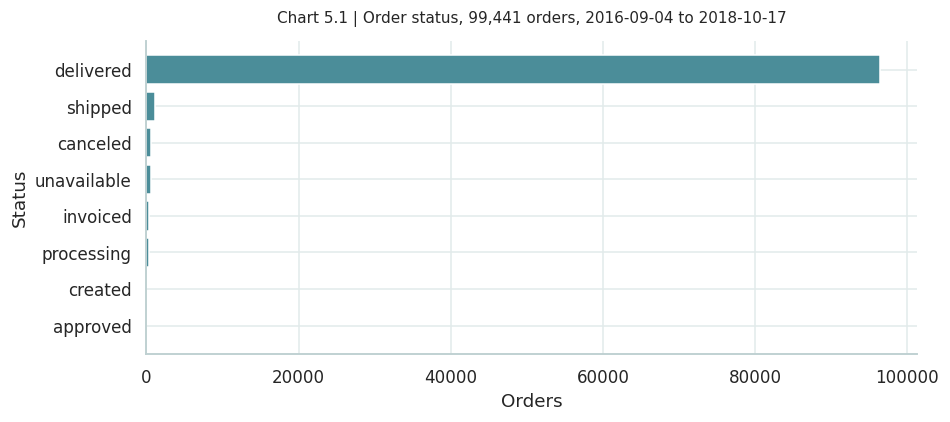

In [6]:
status_summary = orders.order_status.value_counts().rename_axis('order_status').to_frame('orders')
status_summary['share_pct'] = status_summary.orders.div(len(orders)).mul(100)
show_table('5.1', 'Order status counts and shares', status_summary, {'share_pct':'pct'},
      {'orders':'Orders','share_pct':'Share of total'}, sample=f'{len(orders):,} orders', period=ORDER_PERIOD)
fig, ax = plt.subplots(figsize=(8.8,4.0))
ax.barh(status_summary.index, status_summary.orders, color='#4b8d99')
ax.invert_yaxis()
heading(ax,'5.1',f'Order status, {len(orders):,} orders')
axes_labels(ax,'Orders','Status')
complete()

Each status share is recorded in Table 5.1. The delivered share next to the other statuses gives a picture of order completion.



In Table 5.2 the months outside the main window are labeled partial; a small count alone does not prove a month is partial. Chart 5.2 covers the whole continuous window. Table 5.3 separates the two same-month periods and the middle months.



,Orders,Coverage
month,,
2016-09,4,partial
2016-10,324,partial
2016-11,0,partial
2016-12,1,partial
2017-01,800,analysis window
2017-02,"1,780",analysis window
2017-03,"2,682",analysis window
2017-04,"2,404",analysis window
2017-05,"3,700",analysis window


,Orders,Change %
period,,
First same-month period,"22,968",-
Second same-month period,"53,991",135.1%
Two same-month periods,"76,959",-
Middle months,"22,133",-
Whole continuous window,"99,092",-


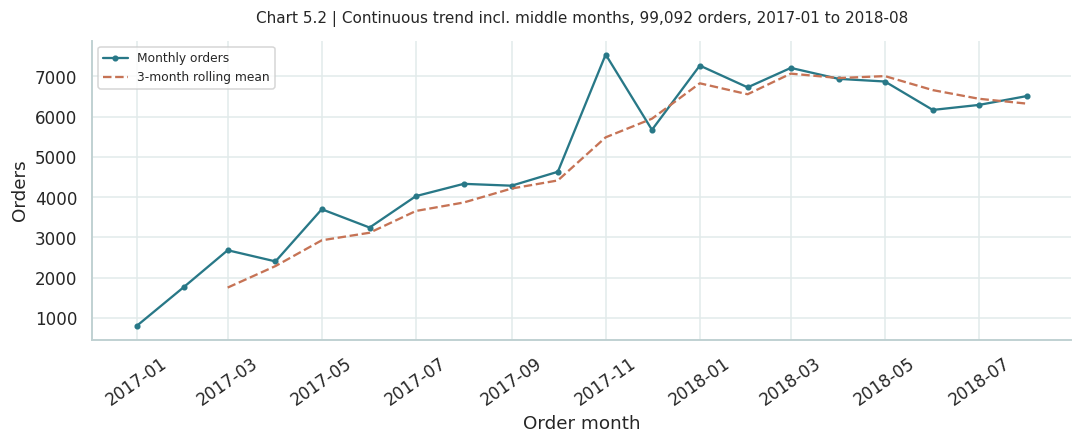

In [7]:
monthly_observed = orders.groupby('purchase_month').size().sort_index()
monthly_all = monthly_observed.reindex(pd.period_range(monthly_observed.index.min(), monthly_observed.index.max(), freq='M'), fill_value=0)
monthly = monthly_all.rename_axis('month').to_frame('orders')
monthly['scope'] = np.where((monthly.index >= START.to_period('M')) & (monthly.index < END.to_period('M')),
                            'analysis window', 'partial')
show_table('5.2', 'Monthly order counts and period coverage', monthly, labels={'orders':'Orders','scope':'Coverage'}, sample=f'{len(orders):,} orders', period=ORDER_PERIOD)
core_monthly = monthly_all.loc[(monthly_all.index >= START.to_period('M')) & (monthly_all.index < END.to_period('M'))]
orders_2017 = int(core_monthly.loc['2017-01':'2017-08'].sum())
orders_2018 = int(core_monthly.loc['2018-01':'2018-08'].sum())
order_growth = (orders_2018 / orders_2017 - 1) * 100
mid_orders = int(core_monthly.sum()) - orders_2017 - orders_2018
period_orders = pd.DataFrame({'period':['First same-month period','Second same-month period','Two same-month periods','Middle months','Whole continuous window'],
                              'orders':[orders_2017,orders_2018,orders_2017+orders_2018,mid_orders,int(core_monthly.sum())],
                              'growth_pct':[np.nan,order_growth,np.nan,np.nan,np.nan]}).set_index('period')
assert orders_2017 + orders_2018 + mid_orders == int(core_monthly.sum())
show_table('5.3','Same-month periods vs middle months',period_orders,{'growth_pct':'pct'},
      {'orders':'Orders','growth_pct':'Change vs first period'}, sample=f'{int(core_monthly.sum()):,} orders', period=TREND_PERIOD)
fig,ax=plt.subplots(figsize=(10,4.2))
ax.plot(core_monthly.index.to_timestamp(),core_monthly.values,marker='o',markersize=3,color='#287887',label=('Monthly orders'))
ax.plot(core_monthly.index.to_timestamp(),core_monthly.rolling(3).mean().values,ls='--',color='#c67355',label=('3-month rolling mean'))
heading(ax,'5.2',f'Continuous trend incl. middle months, {int(core_monthly.sum()):,} orders',TREND_PERIOD)
axes_labels(ax,'Order month','Orders');ax.legend(fontsize=8);plt.xticks(rotation=35);complete()

Chart 5.2 shows the continuous trend and Table 5.3 compares the two same-month periods. The middle months of the first year appear only in the continuous-window total. This distinction matters for capacity planning.



### 5.3. Weekdays and High-Transaction Months

The day order in Chart 5.3 is built from the calendar weekday number. Table 5.4 shows each day's count, Table 5.5 the five highest-volume months and Table 5.6 the highest and lowest months of the analysis window.



,Orders
weekday,
Monday,"16,141"
Tuesday,"15,896"
Wednesday,"15,501"
Thursday,"14,704"
Friday,"14,075"
Saturday,"10,843"
Sunday,"11,932"


,Orders
month,
2017-11,"7,544"
2018-01,"7,269"
2018-03,"7,211"
2018-04,"6,939"
2018-05,"6,873"


,Month,Orders
kind,,
Highest,2017-11,"7,544"
Lowest,2017-01,800


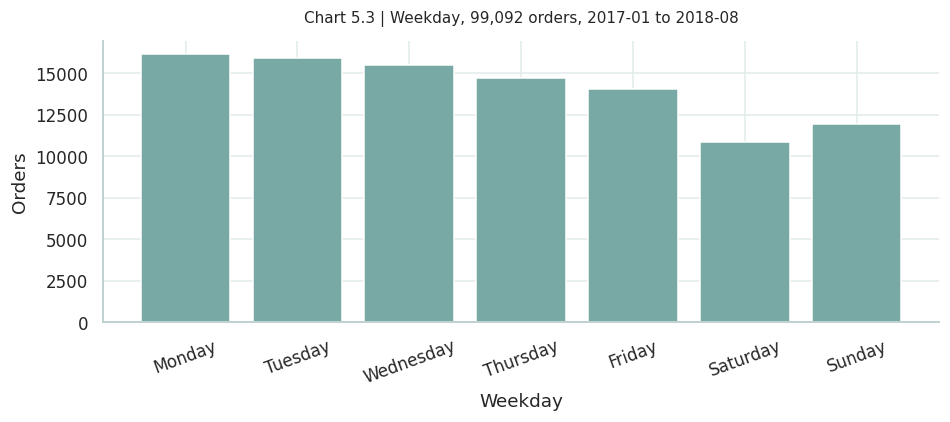

In [8]:
core_orders = orders.loc[orders.order_purchase_timestamp.ge(START) & orders.order_purchase_timestamp.lt(END)].copy()
weekday_names = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_counts = core_orders.purchase_weekday.value_counts().reindex(range(7),fill_value=0)
weekday_table = pd.DataFrame({'weekday':weekday_names,'orders':weekday_counts.to_numpy()}).set_index('weekday')
show_table('5.4','Orders by weekday within analysis window',weekday_table,labels={'orders':'Orders'}, sample=f'{len(core_orders):,} orders', period=TREND_PERIOD)
top_months=core_monthly.sort_values(ascending=False).head(5).rename_axis('month').to_frame('orders')
show_table('5.5','Five months with most orders in analysis window',top_months,labels={'orders':'Orders'}, sample=f'{len(core_orders):,} orders', period=TREND_PERIOD)
monthly_extremes=pd.DataFrame({'kind':['Highest','Lowest'],
    'month':[str(core_monthly.idxmax()),str(core_monthly.idxmin())],
    'orders':[int(core_monthly.max()),int(core_monthly.min())]}).set_index('kind')
show_table('5.6','Highest and lowest months of analysis window',monthly_extremes,labels={'month':'Month','orders':'Orders'}, sample=f'{len(core_orders):,} orders', period=TREND_PERIOD)
fig,ax=plt.subplots(figsize=(8.8,4))
ax.bar([(x) for x in weekday_names],weekday_counts.to_numpy(),color='#79a9a4')
heading(ax,'5.3',f'Weekday, {len(core_orders):,} orders',TREND_PERIOD)
axes_labels(ax,'Weekday','Orders');plt.xticks(rotation=20);complete()

Monday has the most and Saturday the fewest orders in the selected window; the counts are in Table 5.4. The five highest-volume months (Table 5.5) are November 2017 plus four months of 2018, so they are spread across both years rather than confined to a single season; the gap between the busiest and the quietest weekday is about 48% (16,141 vs 10,843 orders).

The weekly distribution is useful for support shift planning and for reviewing order-processing capacity.



# 6. Customers and Geographic Market

The marketing team wants to know where Olist customers are concentrated and how dependent the current market is on a few regions.

## Questions and Activities

### 6.1. Customer Counts

1. Compute the number of unique customers. When counting customers, consider the difference between the row count and the unique-customer count.

### 6.2. Customers by State

2. Compute the customer count per state. Identify the ten states with the most customers and show them in a ranked chart.
3. What share of all customers do the top five states hold? Compute each state's share and the combined share of these five states. Is a large part of the customer base concentrated in a few states?

### 6.3. Customers by City

4. Identify the ten cities with the most customers. Compare the results with the states that have the most customers. Is customer concentration in a few large cities also visible?

### 6.4. Customers vs Orders

5. Compare the customer count of each state with the number of orders placed from that state. Are there states with many customers whose share of orders does not match that count?
6. To answer, show customers and orders together in a comparison or relational chart. Point out the notable differences.

## Business Conclusion

In which regions is Olist's market concentrated? Which regions are worth investigating further for market development?

Keep in mind that a low customer count by itself does not prove a growth opportunity.

---



### 6.1. Unique Customers and State Spread

The stable customer identifier is used for unique counting. If a customer appears in several locations, Chart 6.1 and Tables 6.1-6.3 use the last recorded location. That location is not necessarily the customer's current one.



,Unique customers,Single-order customers,Single-order share,Top-5 state share
0,"96,096","93,099",96.9%,77.1%


,Unique customers,Customer share
customer_state,,
SP,"40,296",41.9%
RJ,"12,381",12.9%
MG,"11,252",11.7%
RS,"5,276",5.5%
PR,"4,879",5.1%
SC,"3,531",3.7%
BA,"3,275",3.4%
DF,"2,072",2.2%
ES,"1,964",2.0%


,,Unique customers
customer_city,customer_state,
sao paulo,SP,"14,972"
rio de janeiro,RJ,"6,612"
belo horizonte,MG,"2,669"
brasilia,DF,"2,065"
curitiba,PR,"1,462"
campinas,SP,"1,396"
porto alegre,RS,"1,326"
salvador,BA,"1,207"
guarulhos,SP,"1,151"


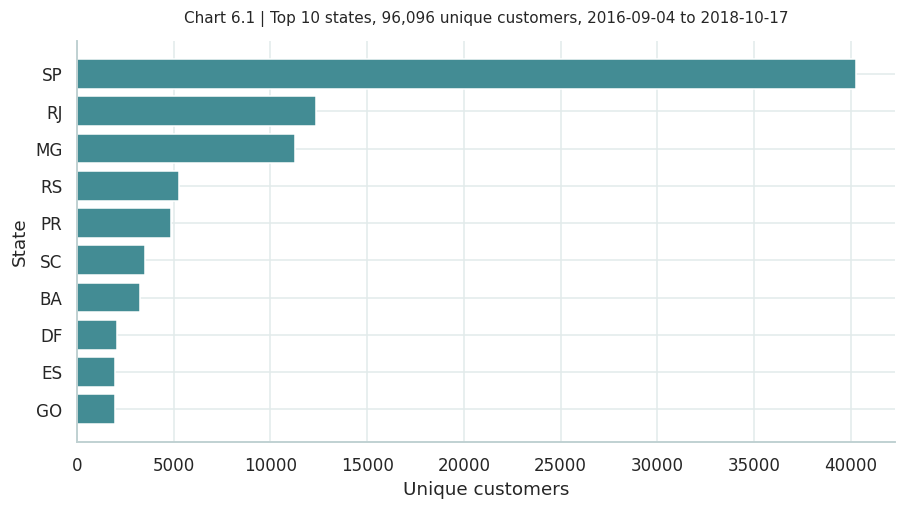

In [9]:
latest_customer = (order_customer.sort_values(['order_purchase_timestamp','order_id'])
                   .drop_duplicates('customer_unique_id',keep='last'))
unique_customers = int(order_customer.customer_unique_id.nunique())
state_customers = latest_customer.groupby('customer_state').customer_unique_id.nunique().sort_values(ascending=False)
state_summary = state_customers.to_frame('customers')
state_summary['share_pct'] = state_summary.customers.div(unique_customers).mul(100)
top5_state_share = state_summary.head(5).share_pct.sum()
customer_order_counts = order_customer.groupby('customer_unique_id').order_id.nunique()
single_customers = int(customer_order_counts.eq(1).sum())
customer_overview = pd.DataFrame({'unique_customers':[unique_customers],
                                  'single_order_customers':[single_customers],
                                  'single_order_pct':[single_customers/unique_customers*100],
                                  'top5_state_pct':[top5_state_share]})
show_table('6.1','Customers and state concentration',customer_overview,
      {'single_order_pct':'pct','top5_state_pct':'pct'},
      {'unique_customers':'Unique customers','single_order_customers':'Single-order customers',
       'single_order_pct':'Single-order share','top5_state_pct':'Top-5 state share'}, sample=f'{unique_customers:,} customers', period=ORDER_PERIOD)
show_table('6.2','Top 10 states by unique customers',state_summary.head(10),{'share_pct':'pct'},
      {'customers':'Unique customers','share_pct':'Customer share'}, sample=f'{unique_customers:,} customers', period=ORDER_PERIOD)
city_summary = (latest_customer.groupby(['customer_city','customer_state']).customer_unique_id.nunique()
                .sort_values(ascending=False).head(10).to_frame('customers'))
show_table('6.3','Top 10 cities by unique customers',city_summary,labels={'customers':'Unique customers'}, sample=f'{unique_customers:,} customers', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.4,4.8))
st=state_summary.head(10)
ax.barh(st.index,st.customers,color='#438c94');ax.invert_yaxis()
heading(ax,'6.1',f'Top 10 states, {unique_customers:,} unique customers, full period')
axes_labels(ax,'Unique customers','State');complete()

The state shares and the customer total are in Tables 6.1 and 6.2.

Market concentration matters for prioritizing services; few customers in a region by itself does not prove a growth opportunity.



### 6.2. Customers vs Orders and Repeat Behavior

In Table 6.4 the order share and the customer share are not on the same basis: orders are counted by the location of each order and customers by their last recorded location. To avoid overlapping labels, Chart 6.2 does not repeat a label on each point; the state names are in the table.



,Unique customers,Customer share,Orders,Order share,"Share gap, pp"
customer_state,,,,,
SP,"40,296",41.9%,"41,746",42.0%,0.0
RJ,"12,381",12.9%,"12,852",12.9%,0.0
MG,"11,252",11.7%,"11,635",11.7%,-0.0
RS,"5,276",5.5%,"5,466",5.5%,0.0
PR,"4,879",5.1%,"5,045",5.1%,-0.0
SC,"3,531",3.7%,"3,637",3.7%,-0.0
BA,"3,275",3.4%,"3,380",3.4%,-0.0
DF,"2,072",2.2%,"2,140",2.2%,-0.0
ES,"1,964",2.0%,"2,033",2.0%,0.0


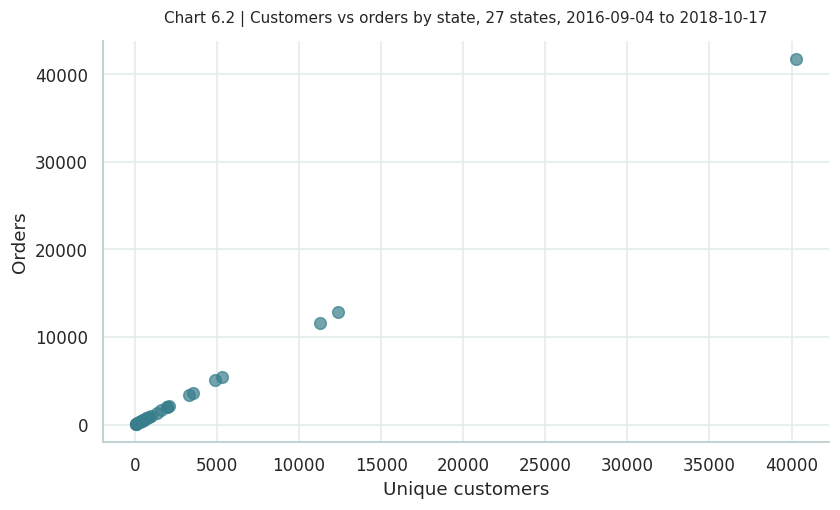

In [10]:
state_orders = order_customer.groupby('customer_state').order_id.nunique().rename('orders')
state_comparison = state_summary.join(state_orders,how='outer').fillna(0)
state_comparison['order_pct'] = state_comparison.orders.div(len(orders)).mul(100)
state_comparison['gap_pp'] = state_comparison.order_pct - state_comparison.share_pct
state_comparison = state_comparison.sort_values('customers',ascending=False)
show_table('6.4','Customers and orders by state',state_comparison,
      {'share_pct':'pct','order_pct':'pct','gap_pp':'pp'},
      {'customers':'Unique customers','share_pct':'Customer share','orders':'Orders',
       'order_pct':'Order share','gap_pp':'Share gap, pp'}, sample=f'{len(order_customer):,} orders', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(7.8,4.8))
ax.scatter(state_comparison.customers,state_comparison.orders,s=58,alpha=.7,color='#387e8c')
heading(ax,'6.2',f'Customers vs orders by state, {len(state_comparison):,} states, full data period')
axes_labels(ax,'Unique customers','Orders');complete()

In Chart 6.2 customers and orders move together in most states. Table 6.4 shows the share differences. This gap by itself does not explain customer-behavior differences.



### 6.3. Second Order Under an Equal Observation Window

Table 6.5 computes the second-order rate for customers who had the same opportunity to order again. The first order in the data is not necessarily the customer's real first purchase.



,Eligible customers,Second order,Second-order rate
0,"77,482","1,827",2.4%


,Customers,Second order,Second-order rate
month,,,
2017-01,764,30,3.9%
2017-02,"1,752",31,1.8%
2017-03,"2,636",67,2.5%
2017-04,"2,352",50,2.1%
2017-05,"3,596",107,3.0%
2017-06,"3,139",93,3.0%
2017-07,"3,894",105,2.7%
2017-08,"4,184",118,2.8%
2017-09,"4,130",121,2.9%


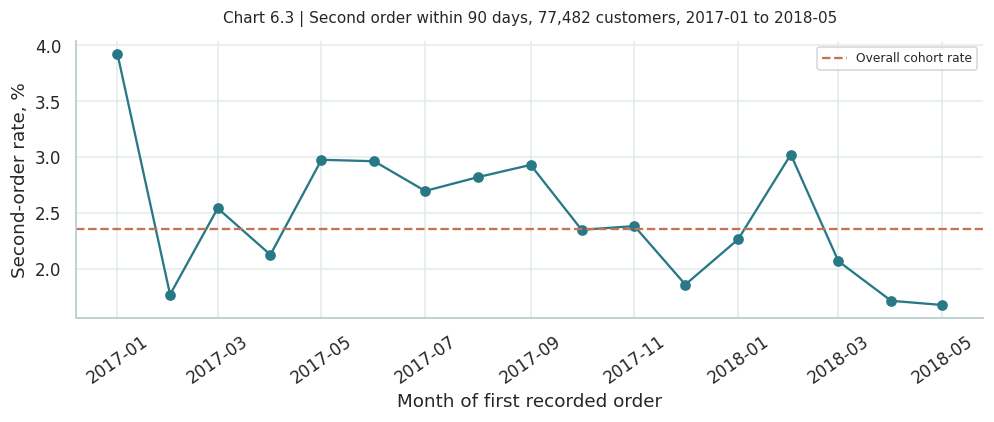

In [11]:
ranked_orders=(order_customer[['customer_unique_id','order_id','order_purchase_timestamp']]
               .dropna(subset=['customer_unique_id','order_purchase_timestamp'])
               .sort_values(['customer_unique_id','order_purchase_timestamp','order_id']).copy())
ranked_orders['position']=ranked_orders.groupby('customer_unique_id').cumcount()
first_order=ranked_orders.loc[ranked_orders.position.eq(0)].set_index('customer_unique_id').order_purchase_timestamp.rename('first_order')
second_order=ranked_orders.loc[ranked_orders.position.eq(1)].set_index('customer_unique_id').order_purchase_timestamp.rename('second_order')
cohorts=pd.concat([first_order,second_order],axis=1)
cohorts=cohorts.loc[cohorts.first_order.ge(START)&cohorts.first_order.lt(COHORT_END)].copy()
cohorts['repeat_90d']=cohorts.second_order.notna() & cohorts.second_order.le(cohorts.first_order+pd.Timedelta(days=WINDOW_DAYS))
cohorts['month']=cohorts.first_order.dt.to_period('M')
cohort_month=cohorts.groupby('month').repeat_90d.agg(customers='size',repeat_customers='sum')
cohort_month['repeat_pct']=cohort_month.repeat_customers.div(cohort_month.customers).mul(100)
repeat_90d_pct=cohorts.repeat_90d.mean()*100
cohort_total=pd.DataFrame({'customers':[len(cohorts)],'repeat_customers':[int(cohorts.repeat_90d.sum())],'repeat_pct':[repeat_90d_pct]})
show_table('6.5',f'Second order within {WINDOW_DAYS} days',cohort_total,{'repeat_pct':'pct'},
      {'customers':'Customers with observation window','repeat_customers':'Customers with second order','repeat_pct':'Second-order rate'}, sample=f'{len(cohorts):,} customers', period=COHORT_PERIOD)
show_table('6.6','Second order by month of first recorded order',cohort_month,{'repeat_pct':'pct'},
      {'customers':'Customers','repeat_customers':'Customers with second order','repeat_pct':'Second-order rate'}, sample=f'{len(cohorts):,} customers', period=COHORT_PERIOD)
fig,ax=plt.subplots(figsize=(9.2,4))
ax.plot(cohort_month.index.to_timestamp(),cohort_month.repeat_pct,marker='o',color='#287887')
ax.axhline(repeat_90d_pct,ls='--',color='#c67355',label=('Overall cohort rate'))
heading(ax,'6.3',f'Second order within {WINDOW_DAYS} days, {len(cohorts):,} customers',COHORT_PERIOD)
axes_labels(ax,'Month of first recorded order','Second-order rate, %');ax.legend(fontsize=8);plt.xticks(rotation=35);complete()

The second-order rate in Table 6.5 has a different denominator and window than the full-period single-order share in Table 6.1. Comparing the two groups in a retention experiment is more reliable with this metric.



# 7. Products and Sales Performance

The sales team wants to know which product categories generate the most demand and which create the most sales value.

## Questions and Activities

### 7.1. Items Sold

1. Compute the number of product categories and identify those with the most items sold. Show the top ten categories in a ranked chart.

### 7.2. Sales Value

2. Compute the sales value of order items using the price column. Aggregate the sales value per category and identify the ten categories with the highest sales value. Show the results in a separate chart.
3. Compare the ranking of categories by items sold with their ranking by sales value. Are there categories with high unit sales that rank lower by sales value? Identify a few examples.

### 7.3. Average Price

4. Compute the average price of sold items per category. Find the five categories with the highest average price. Are these categories necessarily among the best sellers?

### 7.4. Category Share of Sales

5. Compute each category's share of total sales value. What percentage of total sales value do the top five categories form?
6. Examine items sold and sales value per category simultaneously. Plot a relational chart to identify categories that perform differently on unit sales and on sales value.

## Business Conclusion

Which categories matter more by sales volume and which by sales value? Why can deciding product performance on unit sales alone be misleading?

**Note:** the sales value of items is computed from the price recorded in the order-items table and is not necessarily equal to the company's net revenue.

---



### 7.1. Category Items and Value

The base of Tables 7.1, 7.2, 7.3, 7.4 and Charts 7.1-7.2 is delivered-order items only. Category names are the English translation keys. The unknown category stays in the total-value denominator. For categories with no entry in the translation table, Table 7.6 keeps the raw key and no new name is invented. Freight, costs and profit are not part of the goods value.



,Items,Unique orders,Delivered value,Items rank,Value share
category,,,,,
bed_bath_table,"10,953","9,272","1,023,434.76 BRL",1,7.7%
health_beauty,"9,465","8,647","1,233,131.72 BRL",2,9.3%
sports_leisure,"8,431","7,530","954,852.55 BRL",3,7.2%
furniture_decor,"8,160","6,307","711,927.69 BRL",4,5.4%
computers_accessories,"7,644","6,530","888,724.61 BRL",5,6.7%
housewares,"6,795","5,743","615,628.69 BRL",6,4.7%
watches_gifts,"5,859","5,495","1,166,176.98 BRL",7,8.8%
telephony,"4,430","4,093","309,860.23 BRL",8,2.3%
garden_tools,"4,268","3,448","470,495.28 BRL",9,3.6%


,Items,Unique orders,Delivered value,Value rank,Value share
category,,,,,
health_beauty,"9,465","8,647","1,233,131.72 BRL",1,9.3%
watches_gifts,"5,859","5,495","1,166,176.98 BRL",2,8.8%
bed_bath_table,"10,953","9,272","1,023,434.76 BRL",3,7.7%
sports_leisure,"8,431","7,530","954,852.55 BRL",4,7.2%
computers_accessories,"7,644","6,530","888,724.61 BRL",5,6.7%
furniture_decor,"8,160","6,307","711,927.69 BRL",6,5.4%
housewares,"6,795","5,743","615,628.69 BRL",7,4.7%
cool_stuff,"3,718","3,559","610,204.10 BRL",8,4.6%
auto,"4,140","3,810","578,966.65 BRL",9,4.4%


,Items,Unique orders,Delivered value,Items rank,Value rank
category,,,,,
bed_bath_table,"10,953","9,272","1,023,434.76 BRL",1,3
health_beauty,"9,465","8,647","1,233,131.72 BRL",2,1
sports_leisure,"8,431","7,530","954,852.55 BRL",3,4
furniture_decor,"8,160","6,307","711,927.69 BRL",4,6
computers_accessories,"7,644","6,530","888,724.61 BRL",5,5
housewares,"6,795","5,743","615,628.69 BRL",6,7
watches_gifts,"5,859","5,495","1,166,176.98 BRL",7,2
telephony,"4,430","4,093","309,860.23 BRL",8,14
garden_tools,"4,268","3,448","470,495.28 BRL",9,11


,Delivered value,"Value, all statuses",Top-5 category share
0,"13,221,498.11 BRL","13,591,643.70 BRL",39.8%


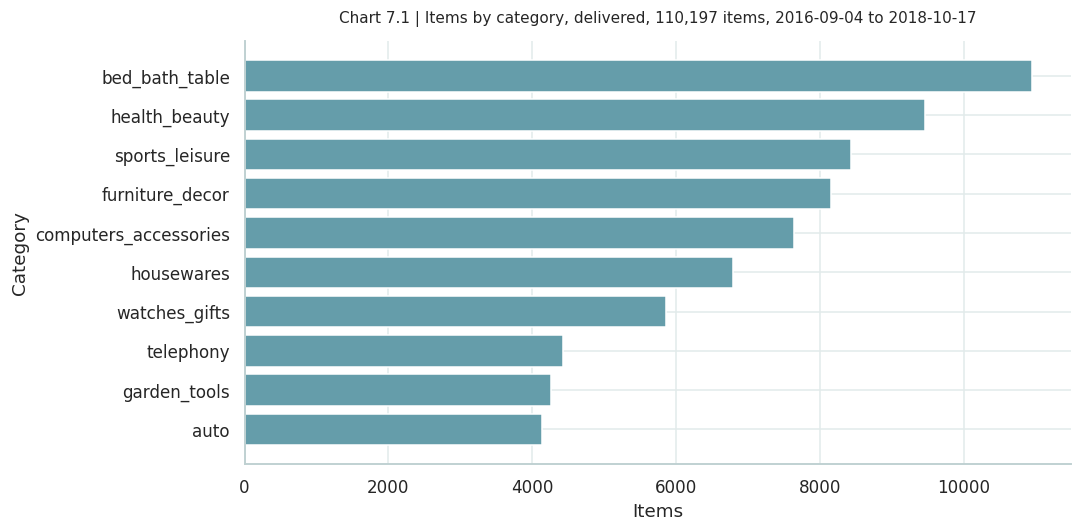

In [12]:
category_sales=(del_items.groupby('category',dropna=False)
                .agg(items=('order_item_id','size'),orders=('order_id','nunique'),
                     value_brl=('price','sum'),mean_price_brl=('price','mean')))
category_sales['item_rank']=category_sales['items'].rank(method='min',ascending=False).astype(int)
category_sales['value_rank']=category_sales.value_brl.rank(method='min',ascending=False).astype(int)
value_delivered=del_items.price.sum()
value_all=items.price.sum()
category_sales['share_pct']=category_sales.value_brl.div(value_delivered).mul(100)
seller_sales=(del_items.groupby('seller_id').agg(items=('order_item_id','size'),
              orders=('order_id','nunique'),value_brl=('price','sum')))
seller_sales['item_rank']=seller_sales['items'].rank(method='min',ascending=False).astype(int)
seller_sales['value_rank']=seller_sales.value_brl.rank(method='min',ascending=False).astype(int)
top_value_categories=category_sales.sort_values('value_brl',ascending=False)
top_item_categories=category_sales.sort_values('items',ascending=False)
top5_category_share=top_value_categories.head(5).share_pct.sum()
labels_cat={'items':'Items','orders':'Unique orders','value_brl':'Delivered goods value, BRL',
            'mean_price_brl':'Mean price, BRL','item_rank':'Items rank','value_rank':'Value rank','share_pct':'Value share'}
formats_cat={'value_brl':'brl','mean_price_brl':'brl','share_pct':'pct'}
show_table('7.1','Top 10 categories by delivered items',top_item_categories.head(10)[['items','orders','value_brl','item_rank','share_pct']],formats_cat,labels_cat, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
show_table('7.2','Top 10 categories by delivered goods value',top_value_categories.head(10)[['items','orders','value_brl','value_rank','share_pct']],formats_cat,labels_cat, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
comparison_names=top_item_categories.head(10).index.union(top_value_categories.head(10).index)
show_table('7.3','Items-rank vs value-rank comparison',category_sales.loc[comparison_names].sort_values('item_rank')[['items','orders','value_brl','item_rank','value_rank']],formats_cat,labels_cat, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
value_summary=pd.DataFrame({'delivered_brl':[value_delivered],'all_status_brl':[value_all],
                            'top5_pct':[top5_category_share]})
show_table('7.4','Headline value and all-status reference',value_summary,
      {'delivered_brl':'brl','all_status_brl':'brl','top5_pct':'pct'},
      {'delivered_brl':'Delivered goods value','all_status_brl':'Goods value, all statuses','top5_pct':'Top-5 category share'}, sample=f'{len(del_items):,} delivered items and {len(items):,} items, all statuses', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(10,5))
top=top_item_categories.head(10)
ax.barh(top.index,top['items'],color='#659daa');ax.invert_yaxis()
heading(ax,'7.1',f'Items by category, delivered, {len(del_items):,} items, full period')
axes_labels(ax,'Items','Category');complete()

The items rank and the value rank differ in Table 7.3. Using both criteria to curate the assortment matters; value alone does not reveal profit.



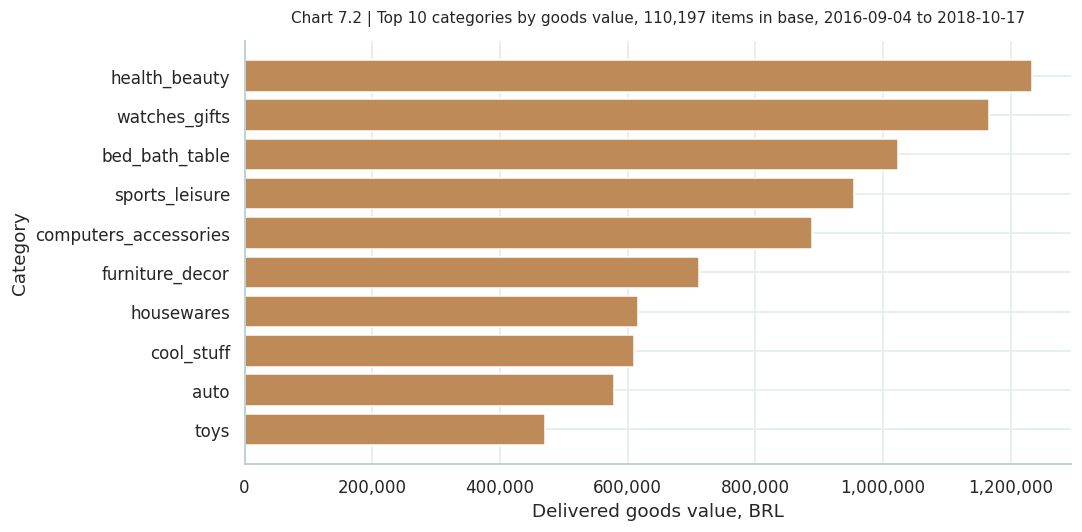

In [13]:
fig,ax=plt.subplots(figsize=(10,5))
top=top_value_categories.head(10)
ax.barh(top.index,top.value_brl,color='#be8a57');ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'))
heading(ax,'7.2',f'Top 10 categories by goods value, {len(del_items):,} items in base')
axes_labels(ax,'Delivered goods value, BRL','Category');complete()

The values of the leading categories are computed in Table 7.2 and the top-five share of the total is in Table 7.4.

Value concentration on a few categories raises the importance of quality checks on those categories, but it does not show profit.



### 7.2. Mean Price and Large Sellers

Table 7.5 shows the five categories with the highest mean price per item, together with their value rank and the number of their sellers present among the top-10 sellers. None of these five categories is in the top ten by value; the value rank and top-seller presence are visible in the same table.



,Items,Delivered value,"Mean price, BRL",Value rank,Top-10 sellers
category,,,,,
computers,199,"218,684.14 BRL","1,098.92 BRL",17,1
small_appliances_home_oven_and_coffee,73,"46,589.56 BRL",638.21 BRL,36,0
home_appliances_2,231,"107,953.95 BRL",467.33 BRL,27,0
agro_industry_and_commerce,206,"70,566.10 BRL",342.55 BRL,30,1
musical_instruments,651,"184,315.74 BRL",283.13 BRL,19,1


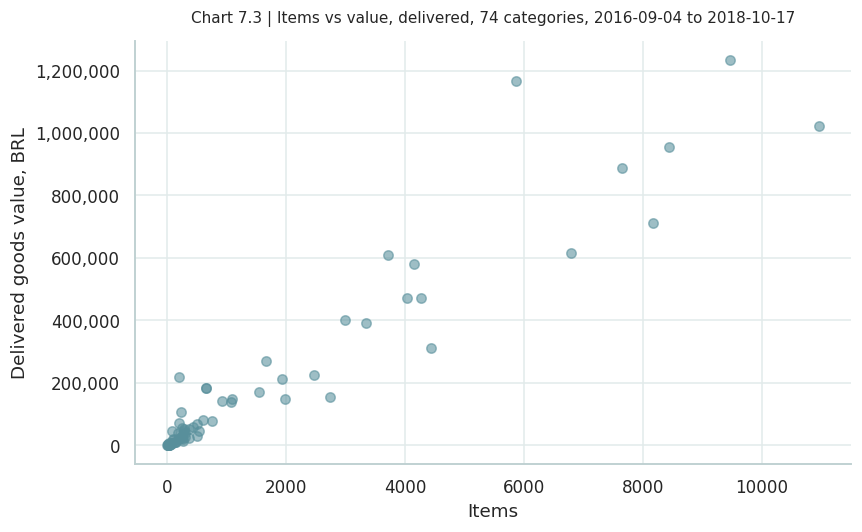

In [14]:
top10_seller_ids=seller_sales.nlargest(10,'value_brl').index
seller_top_presence=(del_items.loc[del_items.seller_id.isin(top10_seller_ids)]
                     .groupby('category').seller_id.nunique().rename('top_sellers'))
expensive=category_sales.sort_values('mean_price_brl',ascending=False).head(5).join(seller_top_presence).fillna({'top_sellers':0})
expensive['top_sellers']=expensive.top_sellers.astype(int)
show_table('7.5','High mean price, value rank and top-seller presence',expensive[['items','value_brl','mean_price_brl','value_rank','top_sellers']],
      formats_cat,{**labels_cat,'top_sellers':'Sellers among top-10 sellers'}, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(category_sales['items'],category_sales.value_brl,alpha=.58,color='#588f9b',s=38)
heading(ax,'7.3',f'Items vs value, delivered, {len(category_sales):,} categories, full period')
axes_labels(ax,'Items','Delivered goods value, BRL')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'));complete()

Chart 7.3 shows the items-value relationship. Table 7.5 shows that a high mean price alone is not enough to lead total value; unit volume matters too.



### 7.3. Keys Missing a Translation

Table 7.7 compares the same-month periods. Table 7.6 shows the raw category keys that have no English equivalent in the translation table. For these cases no substitute name was created and their value stays inside the total.



In [15]:
untranslated_categories=(del_items.loc[del_items.product_category_name.notna() & del_items.product_category_name_english.isna()]
    .groupby('product_category_name').agg(items=('order_item_id','size'),value_brl=('price','sum')))
show_table('7.6','Categories missing from translation table, raw keys',untranslated_categories,
      {'value_brl':'brl'},{'items':'Items','value_brl':'Delivered goods value'}, sample=f'{int(untranslated_categories["items"].sum()):,} items', period=ORDER_PERIOD)

core_del_items = del_items.loc[del_items.order_purchase_timestamp.ge(START) & del_items.order_purchase_timestamp.lt(END)].copy()
delivered_compare_n = int(core_del_items.order_purchase_timestamp.dt.month.lt(END.month).sum())
delivered_period_values = []
for year in (FIRST_YEAR, LAST_YEAR):
    lower = pd.Timestamp(year=year, month=START.month, day=START.day)
    upper = pd.Timestamp(year=year, month=END.month, day=END.day)
    delivered_period_values.append(float(core_del_items.loc[core_del_items.order_purchase_timestamp.ge(lower) &
                                                            core_del_items.order_purchase_timestamp.lt(upper),'price'].sum()))
delivered_growth = (delivered_period_values[1] / delivered_period_values[0] - 1) * 100
delivered_period_table = pd.DataFrame({'period':[str(FIRST_YEAR),str(LAST_YEAR)],
    'value_brl':delivered_period_values,'growth_pct':[np.nan,delivered_growth]}).set_index('period')
show_table('7.7','Delivered goods value in same months',delivered_period_table,
      {'value_brl':'brl','growth_pct':'pct'},{'value_brl':'Delivered value','growth_pct':'Value change'}, sample=f'{delivered_compare_n:,} items in same months', period=TREND_PERIOD)


,Items,Delivered value
product_category_name,,
pc_gamer,8,"1,306.95 BRL"
portateis_cozinha_e_preparadores_de_alimentos,14,"3,933.63 BRL"


,Delivered value,Value change
period,,
2017,"2,993,456.13 BRL",-
2018,"7,218,125.12 BRL",141.1%


# 8. Customer Payment Behavior

The finance team wants to know which payment methods customers use and whether the purchase amount relates to the payment style.

## Questions and Activities

### 8.1. Payment Methods

1. Compute the number of transactions recorded per payment method. Which method is used the most? Also compute each method's share of all payment records and present the results.
2. Compute the total amount paid with each payment method. Does the most-used method also carry the largest total amount?
3. Compute the average payment amount per method. Compare the results and identify which method is associated with a higher average payment.

### 8.2. Installments

4. Examine the distribution of `payment_installments`. How many payments were made with no installment or a single installment? Which installment count is the most common?
5. Examine the relationship between the payment amount and the number of installments. Use a chart that shows the spread of values and the likely relationship between the two variables. Does the installment count usually rise with the payment amount?
6. Examine payments by payment method and installment count. Do different payment methods show different installment patterns?

## Business Conclusion

Which methods do customers use most? Can the purchase amount be one factor related to choosing the number of installments?

**Note:** in the payments table, one row is not necessarily one unique order; choose the counting method correctly when counting orders.

---



### 8.1. Transactions and Payment Methods

Table 8.1 is at transaction level and covers all statuses; one order can have several transactions. The `not_defined` method and zero-value transactions are not removed. Details of mean amounts and zero amounts are in Table 8.9.



,Transactions,Total value,Mean inst.,Multi-installment txns,Transaction share
payment_type,,,,,
credit_card,"76,795","12,542,084.19 BRL",3.51,"51,338",73.9%
boleto,"19,784","2,869,361.27 BRL",1.00,0,19.0%
voucher,"5,775","379,436.87 BRL",1.00,0,5.6%
debit_card,"1,529","217,989.79 BRL",1.00,0,1.5%
not_defined,3,0.00 BRL,1.00,0,0.0%


,Transactions
installments,
0,2
1,"52,546"
2,"12,413"
3,"10,461"
4,"7,098"
5,"5,239"
6,"3,920"
7,"1,626"
8,"4,268"


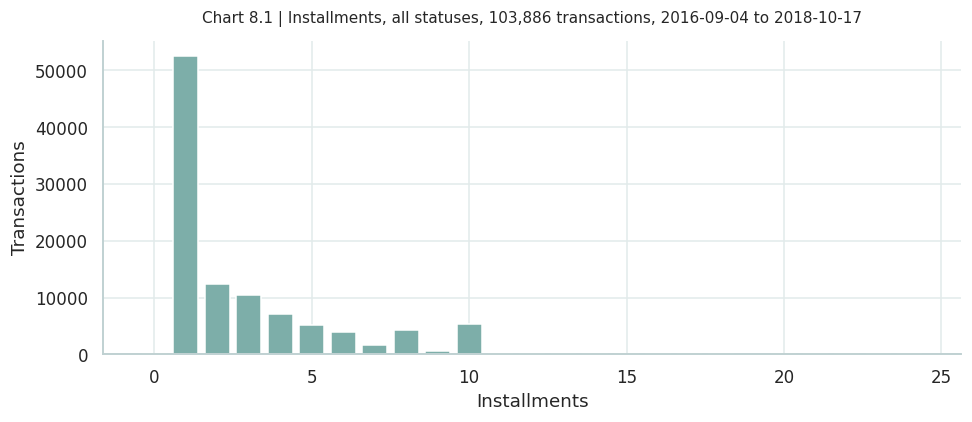

In [16]:
payment_summary=payments.groupby('payment_type').agg(transactions=('order_id','size'),
    total_brl=('payment_value','sum'),mean_brl=('payment_value','mean'),
    mean_installments=('payment_installments','mean'),
    multiple_installments=('payment_installments',lambda s:int(s.gt(1).sum())),
    zero_value=('payment_value',lambda s:int(s.eq(0).sum()))).sort_values('transactions',ascending=False)
payment_summary['share_pct']=payment_summary.transactions.div(len(payments)).mul(100)
show_table('8.1','Payment type, all transactions',payment_summary[['transactions','total_brl','mean_installments','multiple_installments','share_pct']],
      {'total_brl':'brl','mean_brl':'brl','share_pct':'pct','mean_installments':'decimal'},
      {'transactions':'Transactions','total_brl':'Total value','mean_brl':'Mean value',
       'mean_installments':'Mean installments','multiple_installments':'Multi-installment txns',
       'zero_value':'Zero-value txns','share_pct':'Transaction share'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)
installments=payments.payment_installments.value_counts().sort_index().rename_axis('installments').to_frame('transactions')
show_table('8.2','Installments distribution, all transactions',installments,labels={'transactions':'Transactions'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(installments.index.astype(int),installments.transactions,color='#7daea9')
heading(ax,'8.1',f'Installments, all statuses, {len(payments):,} transactions, full period')
axes_labels(ax,'Installments','Transactions');complete()

Chart 8.1 and Table 8.2 show the installment distribution. Table 8.1 shows that multi-installment payments are recorded only for `credit_card`. The difference between methods matters for payment-method design, but it does not measure lost demand.



### 8.2. Value and Installments

Chart 8.2 shows transactions with positive amounts and the count is in the title; the value axis is logarithmic so both large and small values are visible. Table 8.3 separates the rank correlation for all transactions and for credit card. The coefficient summarizes the direction and strength of rank association between -1 and +1; a log axis shows multiplicative distances.



,Transactions,Rank correlation
population,,
all_transactions,"103,886",0.41
credit_card,"76,795",0.48


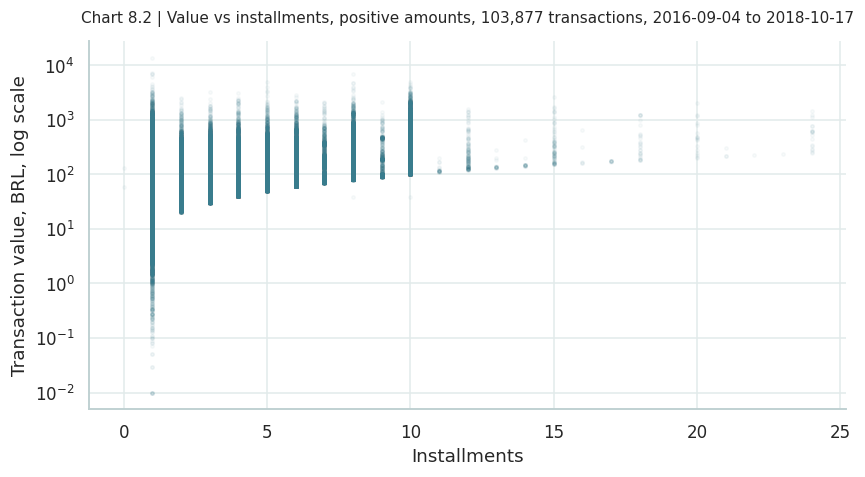

In [17]:
positive_pay=payments.loc[payments.payment_value.gt(0)].copy()
card_pay=payments.loc[payments.payment_type.eq('credit_card')]
payment_rho=payments.payment_value.rank().corr(payments.payment_installments.rank())
card_rho=card_pay.payment_value.rank().corr(card_pay.payment_installments.rank())
payment_relation=pd.DataFrame({'population':['all_transactions','credit_card'],
   'transactions':[len(payments),len(card_pay)],'rank_correlation':[payment_rho,card_rho]}).set_index('population')
show_table('8.3','Rank correlation of value and installments',payment_relation,{'rank_correlation':'decimal'},
      {'transactions':'Transactions','rank_correlation':'Rank correlation'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.scatter(positive_pay.payment_installments,positive_pay.payment_value,s=5,alpha=.035,color='#397c8d')
ax.set_yscale('log')
heading(ax,'8.2',f'Value vs installments, positive amounts, {len(positive_pay):,} transactions, full period')
axes_labels(ax,'Installments','Transaction value, BRL, log scale');complete()

The correlation value in Table 8.3 gives the direction and strength of the rank relationship.

A statistical relationship by itself does not prove that changing installments affects purchases or order value.



### 8.3. Reconciling Payments with Goods and Freight

Tables 8.4-8.8 align payments, goods value and freight for all statuses at order level; item and payment rows are not multiplied against each other. The difference between the `unavailable` and `canceled` statuses and the rest is in Table 8.8. The difference between payments and delivered goods value has a different definition and is recorded separately in Table 8.4. Refund information and the reason for every difference are not available in the data.



In [18]:
payment_by_order=payments.groupby('order_id').agg(paid_brl=('payment_value','sum'),transactions=('payment_value','size'))
item_by_order=items.groupby('order_id').agg(item_brl=('price','sum'),freight_brl=('freight_value','sum'))
reconcile=(orders[['order_id','order_status']].merge(payment_by_order,on='order_id',how='outer')
           .merge(item_by_order,on='order_id',how='outer'))
reconcile['without_item']=reconcile.item_brl.isna()
reconcile[['paid_brl','transactions','item_brl','freight_brl']]=reconcile[['paid_brl','transactions','item_brl','freight_brl']].fillna(0)
reconcile['difference_brl']=reconcile.paid_brl-reconcile.item_brl-reconcile.freight_brl
reconcile['paid_without_item']=reconcile.without_item & reconcile.paid_brl.gt(0)
reconcile['paid_without_item_brl']=reconcile.paid_brl.where(reconcile.without_item,0)
payment_total=payments.payment_value.sum()
freight_all=items.freight_value.sum()
payment_difference=reconcile.difference_brl.sum()
recon_total=pd.DataFrame({'payment_brl':[payment_total],'all_item_brl':[value_all],
                          'freight_brl':[freight_all],'difference_brl':[payment_difference],
                          'delivered_gap_brl':[payment_total-value_delivered]})
show_table('8.4','Total reconciliation, all statuses and transactions',recon_total,
      {x:'brl' for x in recon_total.columns},
      {'payment_brl':'Total payments','all_item_brl':'Goods value, all statuses',
       'freight_brl':'Registered freight','difference_brl':'Difference, all statuses',
       'delivered_gap_brl':'Gap vs delivered'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)
recon_status=reconcile.groupby('order_status',dropna=False).agg(
    orders=('order_id','size'),payment_brl=('paid_brl','sum'),item_brl=('item_brl','sum'),
    freight_brl=('freight_brl','sum'),difference_brl=('difference_brl','sum'),
    no_item_orders=('without_item','sum'),paid_without_item=('paid_without_item','sum'),
    paid_without_item_brl=('paid_without_item_brl','sum'))
show_table('8.5','Difference root-cause by order status',recon_status[['orders','payment_brl','item_brl','freight_brl','difference_brl']],
      {k:'brl' for k in ['payment_brl','item_brl','freight_brl','difference_brl','paid_without_item_brl']},
      {'orders':'Orders','payment_brl':'Payments','item_brl':'Goods','freight_brl':'Freight',
       'difference_brl':'Difference','no_item_orders':'Orders without registered items',
       'paid_without_item':'Paid orders without items','paid_without_item_brl':'Paid without items'}, sample=f'{len(reconcile):,} orders', period=ORDER_PERIOD)
alloc=payments.merge(reconcile[['order_id','paid_brl','difference_brl','transactions']],on='order_id',how='left',validate='many_to_one')
alloc['weight']=np.where(alloc.paid_brl.ne(0),alloc.payment_value.div(alloc.paid_brl),1/alloc.transactions)
alloc['allocated_brl']=alloc.difference_brl*alloc.weight
recon_type=alloc.groupby('payment_type').agg(transactions=('order_id','size'),allocated_brl=('allocated_brl','sum'))
no_payment=reconcile.loc[reconcile.transactions.eq(0),'difference_brl'].sum()
if abs(no_payment)>1e-8:
    recon_type.loc['without_payment']=[0,no_payment]
show_table('8.6','Difference allocation to payment types',recon_type,{'allocated_brl':'brl'},
      {'transactions':'Transactions','allocated_brl':'Allocated difference'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)
no_item_status = recon_status[['no_item_orders','paid_without_item','paid_without_item_brl']]
show_table('8.7','Orders without items and their payments',no_item_status,{'paid_without_item_brl':'brl'},
      {'no_item_orders':'No-item orders','paid_without_item':'Paid, no items','paid_without_item_brl':'No-item value'}, sample=f'{len(reconcile):,} orders', period=ORDER_PERIOD)
payment_residual = recon_status.drop(index=['unavailable','canceled']).difference_brl.sum()
payment_parts = pd.DataFrame({'difference_brl':[recon_status.loc['unavailable','difference_brl'],
    recon_status.loc['canceled','difference_brl'], payment_residual]},
    index=['unavailable','canceled','other_statuses'])
assert np.isclose(payment_parts.difference_brl.sum(), payment_difference)
show_table('8.8','Payment-vs-goods difference parts, all statuses incl. freight',payment_parts,
      {'difference_brl':'brl'},{'difference_brl':'Difference'}, sample=f'{len(reconcile):,} orders', period=ORDER_PERIOD)
show_table('8.9','Mean value and zero amounts by payment type',payment_summary[['mean_brl','zero_value']],
      {'mean_brl':'brl'},{'mean_brl':'Mean payment','zero_value':'Zero-value txns'}, sample=f'{len(payments):,} transactions', period=ORDER_PERIOD)


,Total payments,"Value, all statuses",Registered freight,"Difference, all statuses",Gap vs delivered
0,"16,008,872.12 BRL","13,591,643.70 BRL","2,251,909.54 BRL","165,318.88 BRL","2,787,374.01 BRL"


,Orders,Payments,Goods,Freight,Difference
order_status,,,,,
approved,2,241.08 BRL,209.60 BRL,31.48 BRL,0.00 BRL
canceled,625,"143,255.60 BRL","95,235.27 BRL","10,650.45 BRL","37,369.88 BRL"
created,5,688.10 BRL,0.00 BRL,0.00 BRL,688.10 BRL
delivered,"96,478","15,422,461.77 BRL","13,221,498.11 BRL","2,198,275.64 BRL","2,688.02 BRL"
invoiced,314,"69,137.99 BRL","61,526.37 BRL","7,462.38 BRL",149.24 BRL
processing,301,"69,394.11 BRL","60,439.22 BRL","8,954.89 BRL",0.00 BRL
shipped,"1,107","177,213.96 BRL","150,727.44 BRL","26,401.90 BRL",84.62 BRL
unavailable,609,"126,479.51 BRL","2,007.69 BRL",132.80 BRL,"124,339.02 BRL"


,Transactions,Allocated difference
payment_type,,
boleto,"19,784.00","27,120.98 BRL"
credit_card,"76,795.00","108,770.69 BRL"
debit_card,"1,529.00","2,832.07 BRL"
not_defined,3.00,0.00 BRL
voucher,"5,775.00","26,738.60 BRL"
without_payment,0.00,-143.46 BRL


,No-item orders,"Paid, no items",No-item value
order_status,,,
approved,0,0,0.00 BRL
canceled,164,161,"37,337.87 BRL"
created,5,5,688.10 BRL
delivered,0,0,0.00 BRL
invoiced,2,2,149.23 BRL
processing,0,0,0.00 BRL
shipped,1,1,77.73 BRL
unavailable,603,603,"124,339.02 BRL"


,Difference
unavailable,"124,339.02 BRL"
canceled,"37,369.88 BRL"
other_statuses,"3,609.98 BRL"


,Mean payment,Zero-value txns
payment_type,,
credit_card,163.32 BRL,0
boleto,145.03 BRL,0
voucher,65.70 BRL,6
debit_card,142.57 BRL,0
not_defined,0.00 BRL,3


# 9. Delivery Performance

The operations team wants to assess delivery performance and identify regions or periods that face longer delays.

## Questions and Activities

### 9.1. Delivery Duration

1. For delivered orders, compute the time between purchase and actual delivery in days. Do not include orders whose required dates are missing.
2. Compute the mean, median, minimum and maximum delivery time. What does the gap between mean and median say about the delivery-time distribution?
3. Examine the distribution of delivery times with a histogram or a similar chart. Are most orders delivered within a narrow time range? Is there a small number of orders with extremely long delivery times?

### 9.2. Delivery Delay

4. For each order, compare the actual delivery date with the estimated delivery date. Identify orders delivered before, on and after the estimate. What percentage of delivered orders was late?
5. Compute the mean number of delay days for late orders. Also identify how many orders were more than seven days late.

### 9.3. Geographic and Time Performance

6. Compute the mean delivery time for the customers' states. Identify the ten states with the highest mean delivery time and compare them. To avoid conclusions based on very few orders, also consider each state's order count.
7. Examine the mean delivery time and the percentage of late orders over time. Plot the trend and determine whether these two indicators show improving or worsening delivery performance.

## Business Conclusion

Is delivery delay a widespread problem or concentrated in particular regions and orders? Which indicators are most useful for monitoring delivery performance?

---



### 9.1. Actual Delivery Duration

Table 9.1 covers only delivered orders with valid dates and non-negative duration. The actual duration runs from purchase to delivery. Table 4.1 lists the orders removed from the denominator.



,Orders,"Mean, days","Median, days","Min, days","Max, days"
0,"96,470",12.56,10.22,0.53,209.63


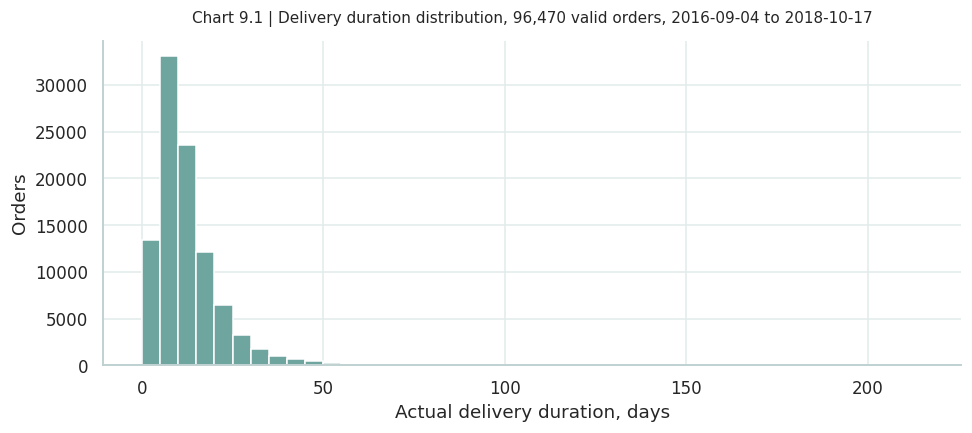

In [19]:
duration_summary=pd.DataFrame({'orders':[len(duration_orders)],'mean_days':[duration_orders.duration_days.mean()],
    'median_days':[duration_orders.duration_days.median()],'min_days':[duration_orders.duration_days.min()],
    'max_days':[duration_orders.duration_days.max()]})
show_table('9.1','Actual delivery duration, orders with valid dates',duration_summary,
      {x:'decimal' for x in ['mean_days','median_days','min_days','max_days']},
      {'orders':'Orders','mean_days':'Mean, days','median_days':'Median, days',
       'min_days':'Min, days','max_days':'Max, days'}, sample=f'{len(duration_orders):,} orders', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(9,4.1))
ax.hist(duration_orders.duration_days,bins=np.arange(0,duration_orders.duration_days.max()+6,5),color='#6ea59e',edgecolor='white')
heading(ax,'9.1',f'Delivery duration distribution, {len(duration_orders):,} valid orders, full period')
axes_labels(ax,'Actual delivery duration, days','Orders');complete()

The mean duration in Table 9.1 is above the median. The median is the middle value of sorted deliveries; a percentile is the boundary of a part of the distribution. Both help identify long deliveries.



### 9.2. Delivery vs Estimated Date

Table 9.2 and Chart 9.2 use the calendar day, not the clock. An order delivered on the promised day is on time and before it is early; the late-rate denominator is only comparable orders.



,Orders,Share of comparable orders
Early,"88,644",91.9%
On time,"1,292",1.3%
Late,"6,534",6.8%


,Comparable orders,Late orders,Late rate,"Mean delay, days",Delayed more than 7 days
0,"96,470","6,534",6.8%,10.62,"2,862"


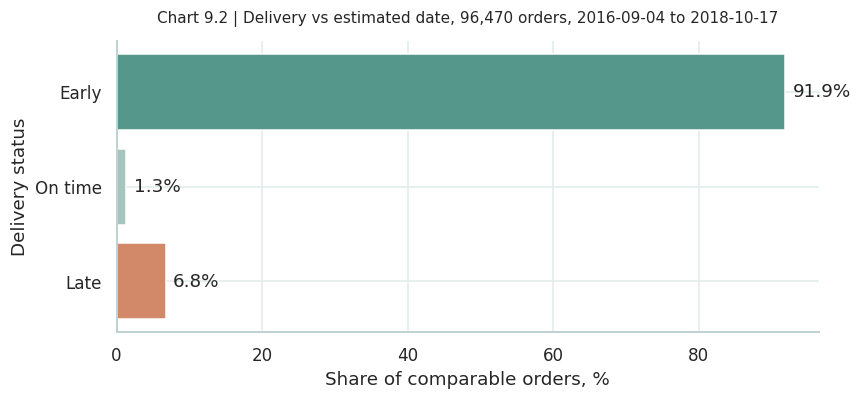

In [20]:
group_keys=['early','on_time','late']
group_labels={'early':'Early','on_time':'On time','late':'Late'}
delivery_groups=delivery.delivery_group.value_counts().reindex(group_keys,fill_value=0).rename_axis('delivery_group').to_frame('orders')
delivery_groups['share_pct']=delivery_groups.orders.div(len(delivery)).mul(100)
delivery_display=delivery_groups.copy();delivery_display.index=[group_labels[x] for x in delivery_display.index]
show_table('9.2','Delivery vs estimated date',delivery_display,{'share_pct':'pct'},
      {'orders':'Orders','share_pct':'Share of comparable orders'}, sample=f'{len(delivery):,} orders', period=ORDER_PERIOD)
late_count=int(delivery.is_late.sum());late_pct=delivery.is_late.mean()*100
late_over7=int(delivery.delay_days.gt(7).sum())
late_mean=delivery.loc[delivery.is_late,'delay_days'].mean()
late_summary=pd.DataFrame({'eligible':[len(delivery)],'late':[late_count],'late_pct':[late_pct],
    'mean_late_days':[late_mean],'over7':[late_over7]})
show_table('9.3','Late rate and severity',late_summary,{'late_pct':'pct','mean_late_days':'decimal'},
      {'eligible':'Comparable orders','late':'Late orders','late_pct':'Late rate',
       'mean_late_days':'Mean delay, days','over7':'Delayed more than 7 days'}, sample=f'{len(delivery):,} orders', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8,3.8))
ax.barh([(group_labels[x]) for x in group_keys],delivery_groups.share_pct,color=['#55988b','#a6c5bd','#d2896a'])
ax.invert_yaxis()
for j,value in enumerate(delivery_groups.share_pct):ax.text(value+1,j,f'{value:.1f}%',va='center')
heading(ax,'9.2',f'Delivery vs estimated date, {len(delivery):,} orders, full period')
axes_labels(ax,'Share of comparable orders, %','Delivery status');complete()

Table 9.2 places the three groups next to the rate and severity in Table 9.3. A long delivery duration is not necessarily a late delivery versus the promise.



### 9.3. Geography and Delay Trend

Table 9.4 ranks states with the stated minimum sample. Table 9.6 puts the same-month periods and March of the second year side by side. Chart 9.3 covers only comparable orders in the continuous window, so its denominator is smaller than the full period.



,Comparable orders,Late orders,"Mean duration, days","Median duration, days",Late rate
customer_state,,,,,
AL,397,85,24.54,22.33,21.4%
MA,717,125,21.57,19.19,17.4%
SE,335,51,21.52,18.01,15.2%
PI,476,66,19.46,16.29,13.9%
CE,"1,279",176,21.27,18.21,13.8%
BA,"3,256",396,19.34,16.91,12.2%
RJ,"12,350","1,495",15.31,12.04,12.1%
PA,946,106,23.77,21.08,11.2%
ES,"1,995",214,15.79,13.64,10.7%


,Comparable orders,Late orders,"Mean duration, days",Late rate
purchase_month,,,,
2017-01,750,22,12.65,2.9%
2017-02,"1,653",49,13.17,3.0%
2017-03,"2,546",116,12.95,4.6%
2017-04,"2,303",151,14.92,6.6%
2017-05,"3,545",106,11.32,3.0%
2017-06,"3,135",95,12.01,3.0%
2017-07,"3,872",108,11.59,2.8%
2017-08,"4,193",122,11.15,2.9%
2017-09,"4,150",182,11.85,4.4%


,Comparable orders,Late orders,Late rate
period,,,
2017-01 to 2017-08,"21,997",769,3.5%
2018-01 to 2018-08,"52,777","4,078",7.7%
2018-03,"7,003","1,328",19.0%


,"Rate change, pp"
0,4.2


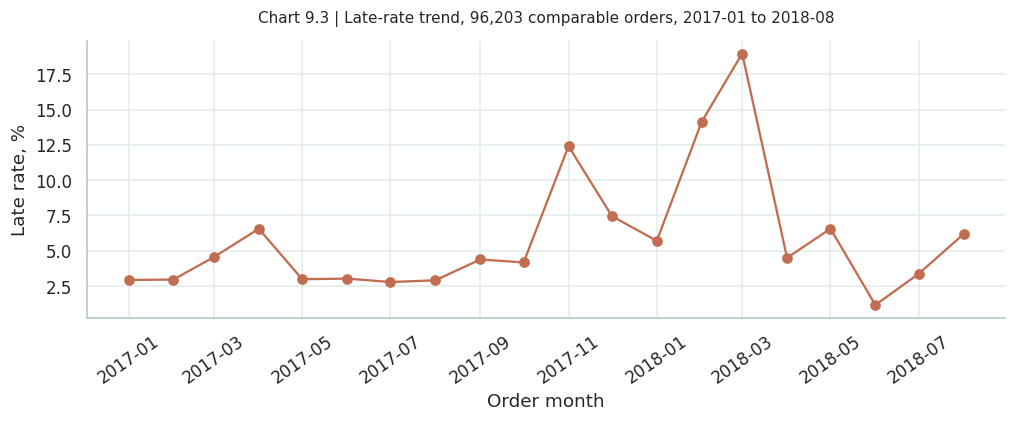

In [21]:
delivery_customer=delivery.merge(customers[['customer_id','customer_state']],on='customer_id',how='left',validate='many_to_one')
state_delivery=(delivery_customer.groupby('customer_state').agg(orders=('order_id','size'),
    late=('is_late','sum'),mean_days=('duration_days','mean'),median_days=('duration_days','median')))
state_delivery['late_pct']=state_delivery.late.div(state_delivery.orders).mul(100)
state_eligible=state_delivery.loc[state_delivery.orders.ge(MIN_STATE)].copy()
show_table('9.4',f'States, at least {MIN_STATE} comparable orders',
      state_eligible.sort_values('late_pct',ascending=False),
      {'late_pct':'pct','mean_days':'decimal','median_days':'decimal'},
      {'orders':'Comparable orders','late':'Late orders','mean_days':'Mean duration, days',
       'median_days':'Median duration, days','late_pct':'Late rate'}, sample=f'{int(state_eligible.orders.sum()):,} orders in eligible states', period=ORDER_PERIOD)
core_delivery=delivery.loc[delivery.order_purchase_timestamp.ge(START)&delivery.order_purchase_timestamp.lt(END)].copy()
monthly_delivery=core_delivery.groupby('purchase_month').agg(orders=('order_id','size'),late=('is_late','sum'),mean_days=('duration_days','mean'))
monthly_delivery['late_pct']=monthly_delivery.late.div(monthly_delivery.orders).mul(100)
show_table('9.5','Monthly late rate and duration in analysis window',monthly_delivery,{'late_pct':'pct','mean_days':'decimal'},
      {'orders':'Comparable orders','late':'Late orders','late_pct':'Late rate','mean_days':'Mean duration, days'}, sample=f'{len(core_delivery):,} orders', period=TREND_PERIOD)
compare_delivery=[]
for year in (FIRST_YEAR,LAST_YEAR):
    sub=core_delivery.loc[core_delivery.order_purchase_timestamp.ge(f'{year}-01-01') &
                          core_delivery.order_purchase_timestamp.lt(f'{year}-09-01')]
    compare_delivery.append({'period':f'{year}-01 to {year}-08','orders':len(sub),
                             'late':int(sub.is_late.sum()),'late_pct':sub.is_late.mean()*100})
march_delivery=core_delivery.loc[core_delivery.purchase_month.eq(pd.Period('2018-03'))]
compare_delivery.append({'period':'2018-03','orders':len(march_delivery),
                         'late':int(march_delivery.is_late.sum()),'late_pct':march_delivery.is_late.mean()*100})
delivery_compare=pd.DataFrame(compare_delivery).set_index('period')
delay_change_pp=delivery_compare.loc['2018-01 to 2018-08','late_pct']-delivery_compare.loc['2017-01 to 2017-08','late_pct']
show_table('9.6',f'Same-month periods and March {LAST_YEAR}',delivery_compare,{'late_pct':'pct'},
      {'orders':'Comparable orders','late':'Late orders','late_pct':'Late rate'}, sample=f'{int(delivery_compare.iloc[0].orders+delivery_compare.iloc[1].orders):,} orders in same months', period=TREND_PERIOD)
show_table('9.7','Late-rate difference between the two periods',pd.DataFrame({'change_pp':[delay_change_pp]}),
      {'change_pp':'pp'},{'change_pp':'Rate change, pp'}, sample=f'{int(delivery_compare.iloc[0].orders+delivery_compare.iloc[1].orders):,} orders in same months', period=TREND_PERIOD)
fig,ax=plt.subplots(figsize=(9.4,4))
ax.plot(monthly_delivery.index.to_timestamp(),monthly_delivery.late_pct,marker='o',color='#c16d51')
heading(ax,'9.3',f'Late-rate trend, {len(core_delivery):,} comparable orders',TREND_PERIOD)
axes_labels(ax,'Order month','Late rate, %');plt.xticks(rotation=35);complete()

The late rate in the two same-month periods and in March is in Table 9.6 with its denominator recorded. Comparing rates, order counts and regions is useful for prioritizing delivery routes; a trend by itself does not reveal cause.



### 9.4. Trend of Mean Actual Delivery Duration

Chart 9.4 shows the mean actual delivery duration for the same months as Table 9.5; Chart 9.3 showed the late rate separately.



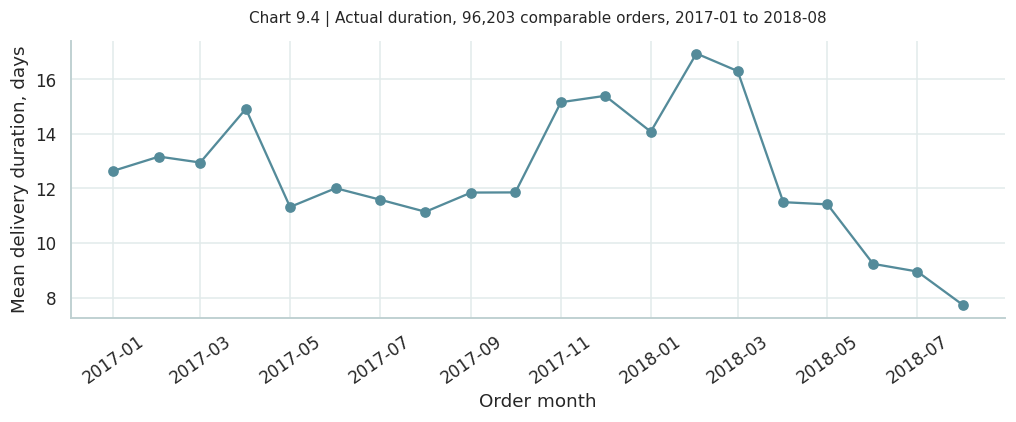

In [22]:
fig,ax=plt.subplots(figsize=(9.4,4))
ax.plot(monthly_delivery.index.to_timestamp(),monthly_delivery.mean_days,marker='o',color='#548b9a')
heading(ax,'9.4',f'Actual duration, {len(core_delivery):,} comparable orders',TREND_PERIOD)
axes_labels(ax,'Order month','Mean delivery duration, days');plt.xticks(rotation=35);complete()

Table 9.5 shows the monthly mean duration and late rate. An apparently falling late rate without a falling actual duration does not necessarily mean faster delivery.



### 9.5. States with the Longest Delivery Durations

Table 9.8 and Chart 9.5 show the states with the highest mean delivery duration after applying the stated sample floor.



,Comparable orders,Late orders,"Mean duration, days","Median duration, days",Late rate
customer_state,,,,,
AM,145,4,26.43,25.88,2.8%
AL,397,85,24.54,22.33,21.4%
PA,946,106,23.77,21.08,11.2%
MA,717,125,21.57,19.19,17.4%
SE,335,51,21.52,18.01,15.2%
CE,"1,279",176,21.27,18.21,13.8%
PB,517,54,20.43,18.15,10.4%
PI,476,66,19.46,16.29,13.9%
RO,243,7,19.37,17.58,2.9%


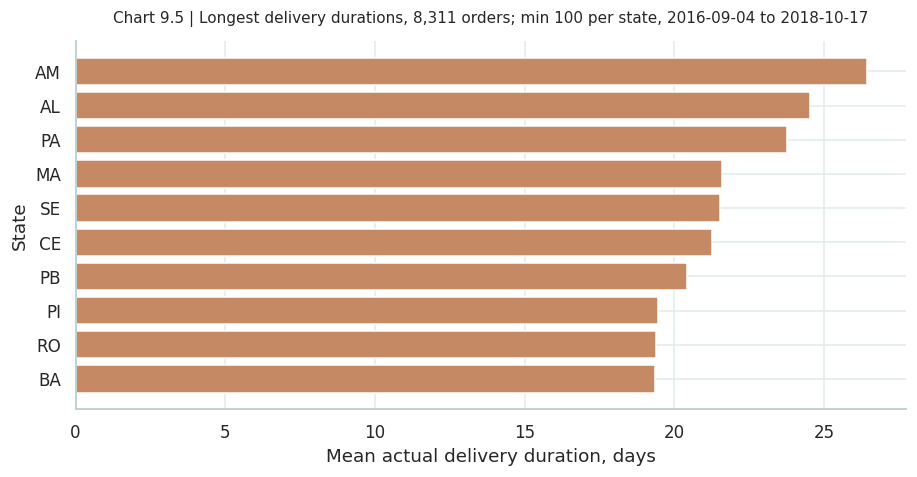

In [23]:
slow_states=state_eligible.nlargest(10,'mean_days')
show_table('9.8',f'Highest mean delivery duration, min {MIN_STATE} orders',slow_states,
      {'late_pct':'pct','mean_days':'decimal','median_days':'decimal'},
      {'orders':'Comparable orders','late':'Late orders','mean_days':'Mean duration, days',
       'median_days':'Median duration, days','late_pct':'Late rate'}, sample=f'{int(slow_states.orders.sum()):,} orders in shown states', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,4.5))
ax.barh(slow_states.index,slow_states.mean_days,color='#c58a63');ax.invert_yaxis()
heading(ax,'9.5',f'Longest delivery durations, {int(slow_states.orders.sum()):,} orders; min {MIN_STATE} per state')
axes_labels(ax,'Mean actual delivery duration, days','State');complete()

Table 9.8 places mean duration, late rate and sample size per state side by side. These three indicators matter when choosing routes to investigate.



# 10. Customer Satisfaction

The customer-experience team wants to know what scores customers leave and how satisfaction differs across product categories and over time.

## Questions and Activities

### 10.1. Score Distribution

1. Compute the number of reviews recorded for each score (`review_score`). Using a distribution chart, identify which scores are the most and least frequent.
2. Compute the mean customer score. Also compute the percentage of reviews with a score of 4 or 5 and the percentage with a score of 1 or 2. Interpret these indicators together.

### 10.2. Satisfaction by Product Category

3. Compute the mean customer score for the different product categories. Identify the ten categories with the highest and the ten with the lowest mean score and show them in a ranked chart.
4. Also check the review count per category. Are categories with very few reviews among the highest or lowest means? Explain why the review count matters when interpreting a mean.

### 10.3. Satisfaction Over Time

5. Compute the mean customer score over time. Plot the change and determine whether a notable rising or falling trend is visible.
6. Compare the mean score and the sales value of product categories. Identify categories with high sales value whose mean score is below the overall average.

## Business Conclusion

What is the overall state of customer satisfaction? Which categories need more investigation and why should a category's performance not be judged on the mean score alone?

---



### 10.1. Score at Review Level

The main basis is the mean over all review records without dropping duplicate identifiers. The order-level mean is labeled separately in Table 10.1; in this data both round to the same two decimals, but their unit of analysis differs.



,Reviews,Review score,Order score,Share of scores 4-5,Share of scores 1-2
0,"99,224",4.09,4.09,77.1%,14.7%


,Reviews,Review share
review_score,,
1,"11,424",11.5%
2,"3,151",3.2%
3,"8,179",8.2%
4,"19,142",19.3%
5,"57,328",57.8%


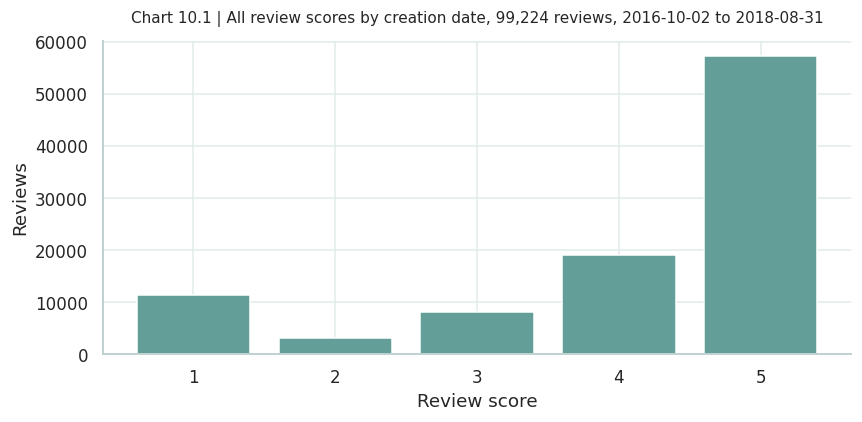

In [24]:
score_counts=reviews.review_score.value_counts().reindex(range(1,6),fill_value=0).rename_axis('review_score').to_frame('reviews')
score_counts['share_pct']=score_counts.reviews.div(len(reviews)).mul(100)
good_pct=reviews.review_score.ge(4).mean()*100
low_pct=reviews.review_score.le(2).mean()*100
score_summary=pd.DataFrame({'reviews':[len(reviews)],'review_mean_score':[review_baseline],
    'order_mean_score':[order_baseline],'positive_pct':[good_pct],'low_pct':[low_pct]})
show_table('10.1','Score basis and group shares',score_summary,
      {'review_mean_score':'score','order_mean_score':'score','positive_pct':'pct','low_pct':'pct'},
      {'reviews':'Reviews','review_mean_score':'Mean review score',
       'order_mean_score':'Mean score per order','positive_pct':'Share of scores 4-5','low_pct':'Share of scores 1-2'}, sample=f'{len(reviews):,} reviews', period=REVIEW_PERIOD)
show_table('10.2','Review score distribution',score_counts,{'share_pct':'pct'},
      {'reviews':'Reviews','share_pct':'Review share'}, sample=f'{len(reviews):,} reviews', period=REVIEW_PERIOD)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(score_counts.index,score_counts.reviews,color='#639e98')
heading(ax,'10.1',f'All review scores by creation date, {len(reviews):,} reviews',REVIEW_PERIOD)
axes_labels(ax,'Review score','Reviews');ax.set_xticks(range(1,6));complete()

Table 10.2 shows each score's share. The mean together with the share of low scores and the review volume gives a fuller picture of the customer experience.



### 10.2. Category Scores with a Sample Floor

Each review belongs to the whole order; if an order spans several categories, the review appears in every related category. Table 10.3 states the sample floor in its title. Chart 10.2 draws the top and bottom categories from the same eligible population.



,Reviews,Reviewed orders,Review score,Score gap,Delivered value
category,,,,,
books_general_interest,492,492,4.53,-0.45,"45,302.15 BRL"
food_drink,223,221,4.45,-0.36,"14,942.88 BRL"
books_imported,50,50,4.44,-0.35,"4,418.86 BRL"
books_technical,257,255,4.43,-0.35,"18,702.23 BRL"
small_appliances_home_oven_and_coffee,72,72,4.43,-0.34,"46,589.56 BRL"
costruction_tools_tools,94,94,4.43,-0.34,"15,903.95 BRL"
luggage_accessories,"1,015","1,015",4.37,-0.28,"138,701.63 BRL"
cine_photo,64,63,4.34,-0.26,"6,674.47 BRL"
food,437,437,4.33,-0.24,"28,731.15 BRL"


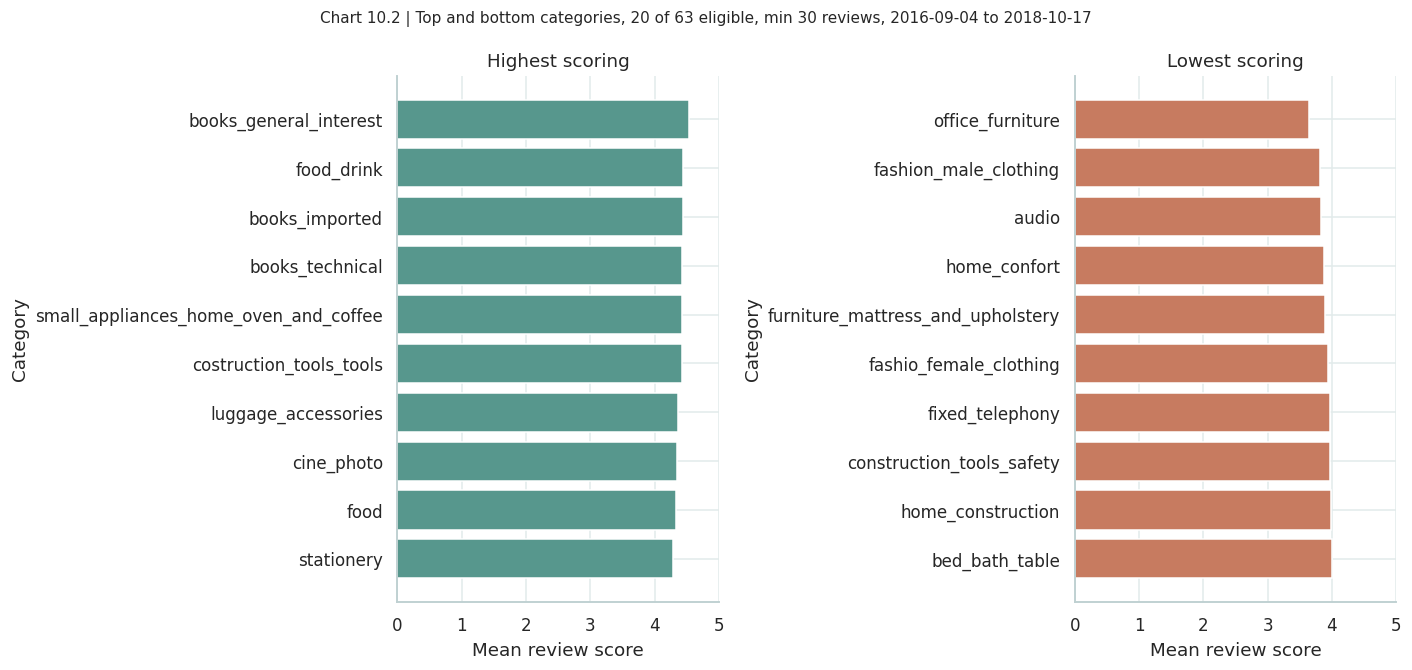

In [25]:
order_category=del_items[['order_id','category']].drop_duplicates()
category_review_rows=order_category.merge(reviews[['order_id','review_score']],on='order_id',how='inner',validate='many_to_many')
category_rating=category_review_rows.groupby('category').agg(review_records=('review_score','size'),
    reviewed_orders=('order_id','nunique'),mean_score=('review_score','mean'))
category_metrics=category_sales.join(category_rating,how='left')
category_metrics['score_gap']=review_baseline-category_metrics.mean_score
category_eligible=category_metrics.loc[category_metrics.review_records.ge(MIN_REVIEWS)].copy()
category_ranked=category_eligible.sort_values('mean_score',ascending=False)
category_formats={'value_brl':'brl','mean_price_brl':'brl','share_pct':'pct','mean_score':'score','score_gap':'score'}
category_labels={**labels_cat,'review_records':'Reviews','reviewed_orders':'Reviewed orders',
                 'mean_score':'Mean review score','score_gap':'Gap vs review baseline'}
show_table('10.3',f'Category scores, at least {MIN_REVIEWS} reviews',
      category_ranked[['review_records','reviewed_orders','mean_score','score_gap','value_brl']],
      category_formats,category_labels, sample=f'{int(category_ranked.review_records.sum()):,} eligible category-review rows', period=ORDER_PERIOD)
fig,axes=plt.subplots(1,2,figsize=(13,6.2))
for ax,part,desc,col in [(axes[0],category_ranked.head(10),'Highest scoring','#57978d'),
                         (axes[1],category_ranked.tail(10).sort_values('mean_score'),'Lowest scoring','#c77b60')]:
    ax.barh(part.index,part.mean_score,color=col);ax.invert_yaxis();ax.set_xlim(0,5)
    ax.set_title((desc));axes_labels(ax,'Mean review score','Category')
fig.suptitle((f'Chart 10.2 | Top and bottom categories, {len(category_ranked.head(10))+len(category_ranked.tail(10)):,} of {len(category_ranked):,} eligible, min {MIN_REVIEWS} reviews, {ORDER_PERIOD}'),fontsize=10)
complete()

The top and bottom ranks can be checked against each category's review count in Table 10.3; categories removed for small samples are listed separately in Table 10.9.

A low score with a sufficient sample is the starting point for investigating the review texts and the order process, not a verdict on product quality.



### 10.3. Monthly Review-Score Trend

The time axis here is the review creation date, not the order date. Table 10.4 shows the monthly trend and Table 10.5 compares the same-month periods and March. Table 10.6 shows the reviews outside the window.



,Reviews
All reviews,"99,224"
Within trend window,"98,899"
Outside trend window,325


,Reviews,Review score
review_month,,
2017-01,239,4.34
2017-02,"1,413",4.28
2017-03,"2,481",4.03
2017-04,"2,055",4.04
2017-05,"3,710",4.10
2017-06,"3,440",4.13
2017-07,"3,503",4.18
2017-08,"4,503",4.22
2017-09,"4,199",4.18


,Reviews,Review score
period,,
2017-01 to 2017-08,"21,344",4.15
2018-01 to 2018-08,"56,164",4.07
2018-03,"7,803",3.73


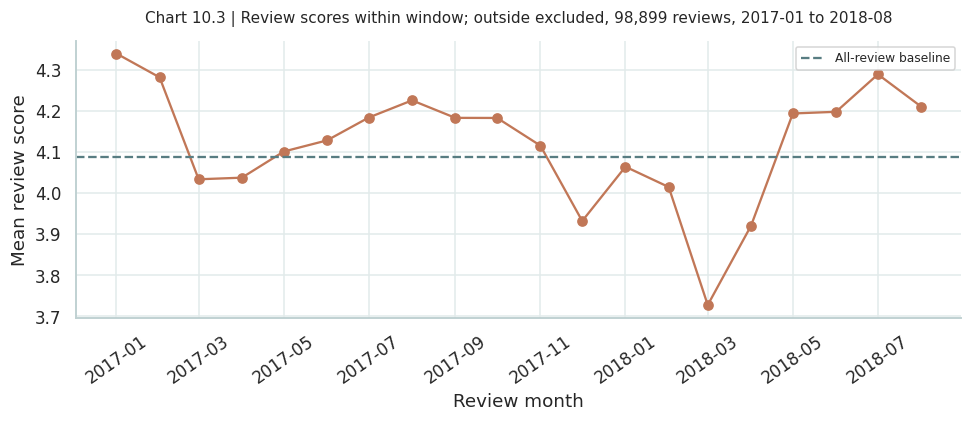

In [26]:
core_reviews=reviews.loc[reviews.review_creation_date.ge(START)&reviews.review_creation_date.lt(END)].copy()
review_coverage = pd.DataFrame({'reviews':[len(reviews),len(core_reviews),len(reviews)-len(core_reviews)]},
    index=['All reviews','Within trend window','Outside trend window'])
show_table('10.6','Review creation date coverage',review_coverage,labels={'reviews':'Reviews'}, sample=f'{len(reviews):,} reviews', period=REVIEW_PERIOD)
core_reviews['review_month']=core_reviews.review_creation_date.dt.to_period('M')
monthly_reviews=core_reviews.groupby('review_month').agg(reviews=('review_score','size'),mean_score=('review_score','mean'))
show_table('10.4','Review score trend by review creation date',monthly_reviews,{'mean_score':'score'},
      {'reviews':'Reviews','mean_score':'Mean review score'}, sample=f'{len(core_reviews):,} reviews', period=TREND_PERIOD)
review_period_rows=[]
for year in (FIRST_YEAR,LAST_YEAR):
    r=core_reviews.loc[core_reviews.review_creation_date.ge(f'{year}-01-01')&core_reviews.review_creation_date.lt(f'{year}-09-01')]
    review_period_rows.append({'period':f'{year}-01 to {year}-08','reviews':len(r),'mean_score':r.review_score.mean()})
march_review=core_reviews.loc[core_reviews.review_month.eq(pd.Period('2018-03'))]
review_period_rows.append({'period':'2018-03','reviews':len(march_review),'mean_score':march_review.review_score.mean()})
review_compare=pd.DataFrame(review_period_rows).set_index('period')
show_table('10.5','Review scores in same-month periods and March',review_compare,{'mean_score':'score'},
      {'reviews':'Reviews','mean_score':'Mean review score'}, sample=f'{int(review_compare.iloc[:2].reviews.sum()):,} reviews in same months', period=TREND_PERIOD)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(monthly_reviews.index.to_timestamp(),monthly_reviews.mean_score,marker='o',color='#c17757')
ax.axhline(review_baseline,ls='--',color='#587d82',label=('All-review baseline'))
heading(ax,'10.3',f'Review scores within window; outside excluded, {len(core_reviews):,} reviews',TREND_PERIOD)
axes_labels(ax,'Review month','Mean review score');ax.legend(fontsize=8);plt.xticks(rotation=35);complete()

The March score in Table 10.5 is below the same-month period averages. Review texts and delivery status are useful for investigating the dip; a trend by itself does not reveal cause.



### 10.4. Category Value and Scores

In Chart 10.4 each point is a category with the sample floor among delivered orders. For a candidate to be flagged, beyond the sample floor a high value and a clear gap from the mean of all reviews are required; the value threshold and the list are in Table 10.7. These rules are a first screening.



,Delivered value,Reviews,Review score,Score gap
category,,,,
office_furniture,"268,154.31 BRL","1,249",3.64,0.44


,Delivered value,Reviews,Review score,Score gap,Candidate
category,,,,,
bed_bath_table,"1,023,434.76 BRL","9,295",4.00,0.09,False
office_furniture,"268,154.31 BRL","1,249",3.64,0.44,True
watches_gifts,"1,166,176.98 BRL","5,464",4.12,-0.03,False


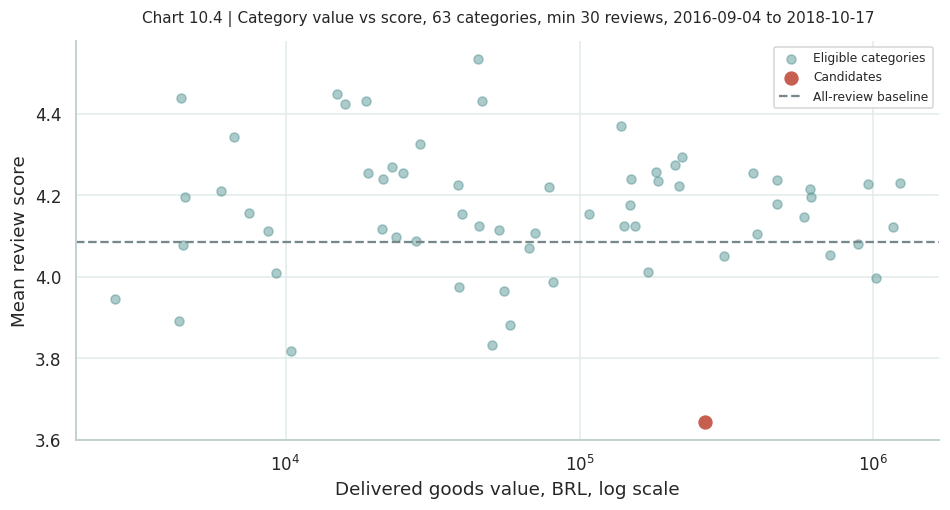

In [27]:
category_value_threshold=category_eligible.value_brl.quantile(.75)
category_candidates=category_eligible.loc[(category_eligible.value_brl.ge(category_value_threshold)) &
                                           (category_eligible.score_gap.ge(SCORE_GAP))].sort_values('value_brl',ascending=False)
category_focus=category_eligible.loc[category_eligible.index.isin(['bed_bath_table','office_furniture','watches_gifts'])].copy()
category_focus['candidate']=category_focus.index.isin(category_candidates.index)
show_table('10.7',f'Category candidates; value at least {category_value_threshold:,.2f} BRL, {MIN_REVIEWS} reviews, gap at least {SCORE_GAP:.2f}',
      category_candidates[['value_brl','review_records','mean_score','score_gap']],category_formats,category_labels, sample=f'{int(category_candidates.review_records.sum()):,} selected category-review rows', period=ORDER_PERIOD)
show_table('10.8',f'Selected categories, min {MIN_REVIEWS} reviews, vs thresholds',
      category_focus[['value_brl','review_records','mean_score','score_gap','candidate']],
      category_formats,{**category_labels,'candidate':'In candidate list'}, sample=f'{int(category_focus.review_records.sum()):,} selected category-review rows', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.8,4.8))
ax.scatter(category_eligible.value_brl,category_eligible.mean_score,s=35,alpha=.5,color='#5a9897',label=('Eligible categories'))
ax.scatter(category_candidates.value_brl,category_candidates.mean_score,s=70,color='#c65f50',label=('Candidates'))
ax.axhline(review_baseline,color='#76888a',ls='--',label=('All-review baseline'))
ax.set_xscale('log')
heading(ax,'10.4',f'Category value vs score, {len(category_eligible):,} categories, min {MIN_REVIEWS} reviews')
axes_labels(ax,'Delivered goods value, BRL, log scale','Mean review score')
ax.legend(fontsize=8);complete()

Table 10.7 separates categories meeting both conditions from categories near the average.

Focusing on an eligible category together with its review volume reduces the chance of acting on a very small difference.



### Categories with Small Samples

Table 10.9 lists categories that did not reach the review floor and were left out of the main ranking. This table exists so small samples are not hidden; it is not a reliable ranking.



In [28]:
category_small=category_metrics.loc[category_metrics.review_records.fillna(0).lt(MIN_REVIEWS)].sort_values('mean_score')
show_table('10.9',f'Small samples, fewer than {MIN_REVIEWS} reviews',
      category_small[['review_records','reviewed_orders','mean_score','value_brl']],category_formats,category_labels, sample=f'{int(category_small.review_records.sum()):,} small-sample category-review rows', period=ORDER_PERIOD)

,Reviews,Reviewed orders,Review score,Delivered value
category,,,,
security_and_services,2,2,2.50,283.29 BRL
pc_gamer,7,7,3.43,"1,306.95 BRL"
portateis_cozinha_e_preparadores_de_alimentos,13,13,3.62,"3,933.63 BRL"
home_comfort_2,23,23,3.83,760.27 BRL
diapers_and_hygiene,25,25,3.96,"1,500.79 BRL"
arts_and_craftmanship,23,23,4.17,"1,814.01 BRL"
la_cuisine,12,12,4.25,"2,054.99 BRL"
flowers,28,28,4.39,"1,110.04 BRL"
fashion_sport,27,26,4.41,"2,094.52 BRL"


# 11. Delivery Delay and Customer Satisfaction

The customer-experience team has hypothesized that a delayed delivery is associated with lower customer satisfaction. Test this hypothesis with the data.

## Questions and Activities

### 11.1. On-Time vs Late Orders

1. Split delivered orders into an "on-time" group and a "late" group. For each group compute the number of orders and the mean customer score.
2. Show the mean scores of the two groups in a comparison chart. How large is the observed difference? Are the group order counts also large enough for the comparison to be meaningful?

### 11.2. Delay Severity

3. Split late orders into bands by the number of delay days, for example:

- 1 to 3 days
- 4 to 7 days
- more than 7 days

Compute the mean score and the number of orders in each band.

4. Show how the mean score changes across delay bands. Does the customer score fall regularly as the delay grows, or is no clear pattern visible?

### 11.3. Differences Across Categories

5. Check whether the observed relationship is the same for all product categories. Select a few categories with enough orders and compare on-time and late scores within them.

## Analytical Conclusion

Do the results support an association between delivery delay and customer satisfaction? What are the limits of this analysis?

Explain why observing this association by itself does not prove that delay causes the lower satisfaction.

---



### 11.1. Score and Delivery Status

Reviews are attached, at record level and without dropping duplicate reviews, to comparable delivered orders. Table 11.1 shows the three delivery groups as Early, On time and Late. Table 11.2 merges the early and on-time groups for comparison with late and keeps the review count and the reviewed-order count separate.



,Reviews,Reviewed orders,Review score
Early,"88,653","88,163",4.29
On time,"1,291","1,280",4.03
Late,"6,409","6,381",2.27


,Reviews,Reviewed orders,Review score,Score gap
Early & on time,"89,944","89,443",4.29,0.00
Late,"6,409","6,381",2.27,2.02


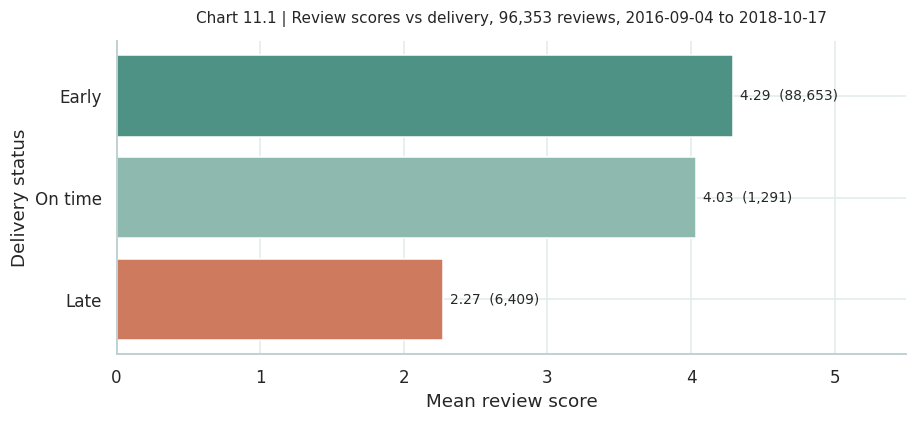

In [29]:
delivery_reviews=delivery[['order_id','delay_days','delivery_group','is_late']].merge(
    reviews[['order_id','review_score']],on='order_id',how='inner',validate='one_to_many')
group_reviews=(delivery_reviews.groupby('delivery_group').agg(review_records=('review_score','size'),
    reviewed_orders=('order_id','nunique'),mean_score=('review_score','mean')).reindex(group_keys))
group_reviews_display=group_reviews.copy();group_reviews_display.index=[group_labels[x] for x in group_reviews.index]
show_table('11.1','Review scores across three delivery statuses',group_reviews_display,{'mean_score':'score'},
      {'review_records':'Reviews','reviewed_orders':'Reviewed orders','mean_score':'Mean review score'}, sample=f'{len(delivery_reviews):,} reviews', period=ORDER_PERIOD)
score_by_late=(delivery_reviews.groupby('is_late').agg(review_records=('review_score','size'),
    reviewed_orders=('order_id','nunique'),mean_score=('review_score','mean')).reindex([False,True]))
score_by_late['gap_score']=score_by_late.loc[False,'mean_score']-score_by_late.mean_score
score_by_late_display=score_by_late.copy();score_by_late_display.index=['Early & on time','Late']
show_table('11.2','Review scores, no-delay vs late',score_by_late_display,{'mean_score':'score','gap_score':'score'},
      {'review_records':'Reviews','reviewed_orders':'Reviewed orders','mean_score':'Mean review score',
       'gap_score':'Gap vs no-delay group'}, sample=f'{len(delivery_reviews):,} reviews', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,4))
ax.barh([(group_labels[x]) for x in group_keys],group_reviews.mean_score,color=['#4e9286','#8eb9ae','#ce7a5f'])
ax.invert_yaxis();ax.set_xlim(0,5.5)
for j,(_,row) in enumerate(group_reviews.iterrows()):
    ax.text(row.mean_score+.05,j,f'{row.mean_score:.2f}  ({int(row.review_records):,})',va='center',fontsize=9)
heading(ax,'11.1',f'Review scores vs delivery, {len(delivery_reviews):,} reviews, full period')
axes_labels(ax,'Mean review score','Delivery status');complete()

Each group's mean and sample size are in Tables 11.1 and 11.2.

The score difference justifies investigating late orders; the association is not causal.



### 11.2. Delay Severity

Table 11.3 and Chart 11.2 include only review records of late orders. Banding uses calendar days after the estimated date. The score basis, as in Table 11.2, is the review record, not a re-aggregation over orders.



,Reviews,Reviewed orders,Review score
1-3 days,"1,856","1,852",3.29
4-7 days,"1,756","1,748",2.10
8+ days,"2,797","2,781",1.70


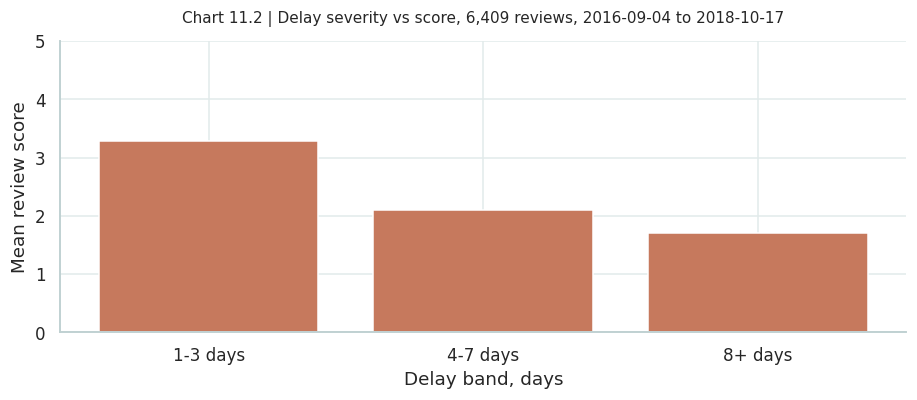

In [30]:
late_reviews=delivery_reviews.loc[delivery_reviews.is_late].copy()
late_reviews['delay_band']=pd.cut(late_reviews.delay_days,bins=[0,3,7,np.inf],labels=['1-3','4-7','8+'])
severity=(late_reviews.groupby('delay_band',observed=True).agg(review_records=('review_score','size'),
    reviewed_orders=('order_id','nunique'),mean_score=('review_score','mean')).reindex(['1-3','4-7','8+']))
severity_display=severity.copy();severity_display.index=['1-3 days','4-7 days','8+ days']
show_table('11.3','Delay severity and review scores',severity_display,{'mean_score':'score'},
      {'review_records':'Reviews','reviewed_orders':'Reviewed orders','mean_score':'Mean review score'}, sample=f'{len(late_reviews):,} reviews', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,3.8))
ax.bar([(x) for x in severity_display.index],severity.mean_score,color='#c6795d')
heading(ax,'11.2',f'Delay severity vs score, {len(late_reviews):,} reviews, full period')
axes_labels(ax,'Delay band, days','Mean review score');ax.set_ylim(0,5);complete()

The mean score falls as the delay band grows; the values and the review and order counts are in Table 11.3.

Longer delays have priority for process and customer-experience investigation, but other factors may also play a role.



### 11.3. Category Comparison

Tables 11.4 and 11.5 compare only categories that reach the sample floor in each of the three statuses Early, On time and Late. Each score column is paired with that group's review count. The early-vs-late difference is provided for comparison and is not necessarily a causal effect of delay.



In [31]:
category_delivery=order_category.merge(delivery[['order_id','delivery_group']],on='order_id',how='inner',validate='many_to_one')
category_delivery=category_delivery.merge(reviews[['order_id','review_score']],on='order_id',how='inner',validate='many_to_many')
cat_group=category_delivery.groupby(['category','delivery_group']).agg(n=('review_score','size'),score=('review_score','mean'))
cat_n=cat_group['n'].unstack('delivery_group').reindex(columns=group_keys).fillna(0)
cat_score=cat_group['score'].unstack('delivery_group').reindex(columns=group_keys)
cat_three=cat_n.ge(MIN_REVIEWS).all(axis=1)
category_delivery_compare=pd.DataFrame({
    'early_n':cat_n.loc[cat_three,'early'],'early_score':cat_score.loc[cat_three,'early'],
    'on_time_n':cat_n.loc[cat_three,'on_time'],'on_time_score':cat_score.loc[cat_three,'on_time'],
    'late_n':cat_n.loc[cat_three,'late'],'late_score':cat_score.loc[cat_three,'late'],
    'gap_score':cat_score.loc[cat_three,'early']-cat_score.loc[cat_three,'late'],
}).sort_values('late_n',ascending=False)
show_table('11.4',f'Category scores, at least {MIN_REVIEWS} reviews per status',
      category_delivery_compare[['early_n','early_score','on_time_n','on_time_score']],
      {'early_score':'score','on_time_score':'score'},
      {'early_n':'Early reviews','early_score':'Early score','on_time_n':'On-time reviews','on_time_score':'On-time score'}, sample=f'{int(cat_n.loc[cat_three].to_numpy().sum()):,} eligible category-review rows', period=ORDER_PERIOD)
show_table('11.5',f'Late category scores, at least {MIN_REVIEWS} reviews per status',
      category_delivery_compare[['late_n','late_score','gap_score']],
      {'late_score':'score','gap_score':'score'},
      {'late_n':'Late reviews','late_score':'Late score','gap_score':'Score gap'}, sample=f'{int(cat_n.loc[cat_three].to_numpy().sum()):,} eligible category-review rows', period=ORDER_PERIOD)

,Early reviews,Early score,On-time reviews,On-time score
category,,,,
bed_bath_table,"8,495.00",4.14,121.00,4.06
health_beauty,"7,891.00",4.38,126.00,4.25
sports_leisure,"6,960.00",4.37,89.00,4.20
furniture_decor,"5,789.00",4.19,87.00,3.74
computers_accessories,"6,052.00",4.21,87.00,3.91
watches_gifts,"5,005.00",4.28,61.00,3.84
housewares,"5,340.00",4.30,90.00,4.19
telephony,"3,728.00",4.18,58.00,4.00
auto,"3,483.00",4.29,50.00,4.12


,Late reviews,Late score,Score gap
category,,,
bed_bath_table,679.00,2.23,1.91
health_beauty,637.00,2.35,2.03
sports_leisure,487.00,2.17,2.20
furniture_decor,441.00,2.33,1.86
computers_accessories,409.00,2.28,1.93
watches_gifts,396.00,2.21,2.07
housewares,300.00,2.26,2.04
telephony,287.00,2.43,1.75
auto,274.00,2.31,1.98


# 12. Seller Performance

Management wants to know how sales are distributed across sellers and whether top-selling sellers also perform well on customer satisfaction.

## Questions and Activities

### 12.1. Seller Counts and Spread

1. Compute the number of unique sellers. Also compute the number of active sellers per state and compare the ten states with the most sellers.

### 12.2. Seller Sales

2. Compute the items sold and the sales value for each seller. Identify the top ten sellers by sales value and show the results in a ranked chart.
3. Compute the top ten sellers' share of total sales value. Is a large part of sales dependent on a limited number of sellers?
4. Rank sellers by items sold. Is their ranking by items the same as their ranking by sales value? Investigate a few notable differences.

### 12.3. Sales and Customer Satisfaction

5. For sellers with enough reviews, compute the mean customer score. Plot sales and score in a relational chart so that top sellers with low scores can be identified.
6. Select a few sellers whose sales are high but whose mean score is below the overall average. Also check their order or review counts to avoid conclusions from very small samples.

## Business Conclusion

Is Olist's sales dependent on a small number of sellers? Which sellers, given their volume and customer score, may need closer review?

---



### 12.1. Seller Counts and State Distribution

Table 12.1 separates unique sellers in the data, sellers with items in all statuses and sellers with delivered items. Table 12.2 and Chart 12.1 show where sellers are located; no current-activity assumption is made for them.



,Unique sellers,With items,Delivered
0,"3,095","3,095","2,970"


,Unique sellers
seller_state,
SP,"1,849"
PR,349
MG,244
SC,190
RJ,171
RS,129
GO,40
DF,30
ES,23


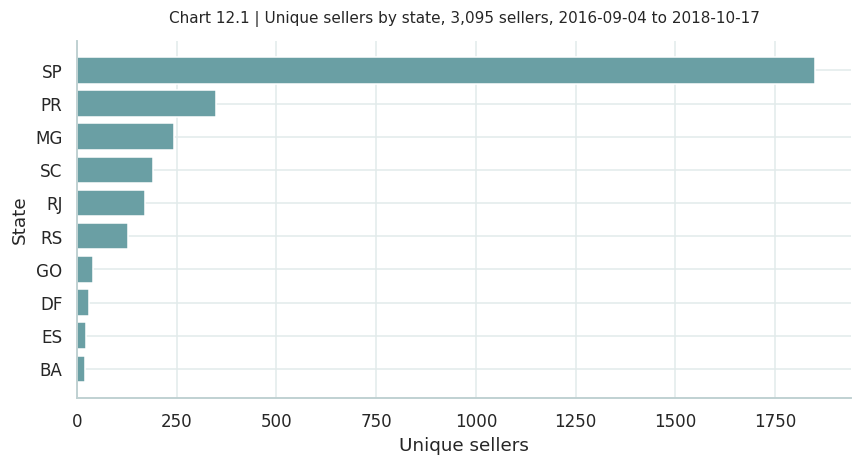

In [32]:
seller_count=pd.DataFrame({'unique_sellers':[sellers.seller_id.nunique()],
    'sellers_with_items':[items.seller_id.nunique()],'sellers_delivered':[del_items.seller_id.nunique()]})
show_table('12.1','Unique seller counts',seller_count,
      labels={'unique_sellers':'Unique sellers','sellers_with_items':'With items, all statuses',
              'sellers_delivered':'With delivered items'}, sample=f'{len(sellers):,} sellers', period=ORDER_PERIOD)
seller_states=sellers.groupby('seller_state').seller_id.nunique().sort_values(ascending=False).head(10).to_frame('sellers')
show_table('12.2','Top 10 states by unique sellers',seller_states,labels={'sellers':'Unique sellers'}, sample=f'{len(sellers):,} sellers', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8,4.4))
ax.barh(seller_states.index,seller_states.sellers,color='#6a9fa4');ax.invert_yaxis()
heading(ax,'12.1',f'Unique sellers by state, {len(sellers):,} sellers, full period')
axes_labels(ax,'Unique sellers','State');complete()

Table 12.2 shows the geographic concentration of unique sellers. That concentration by itself does not determine shipping cost or efficiency.



### 12.2. Seller Value and Items

Tables 12.3, 12.4 and 12.5 put the value rank and the items rank side by side. IDs are shown in full in the tables and shortened in the chart.



,Items,Orders,Delivered value,Items rank,Value rank
seller_id,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,"1,148","1,124","226,987.93 BRL",11,1
53243585a1d6dc2643021fd1853d8905,400,348,"217,940.44 BRL",40,2
4a3ca9315b744ce9f8e9374361493884,"1,949","1,772","196,882.12 BRL",2,3
fa1c13f2614d7b5c4749cbc52fecda94,579,578,"190,917.14 BRL",21,4
7c67e1448b00f6e969d365cea6b010ab,"1,355",973,"186,570.05 BRL",8,5
7e93a43ef30c4f03f38b393420bc753a,322,319,"165,981.49 BRL",59,6
da8622b14eb17ae2831f4ac5b9dab84a,"1,548","1,311","159,816.87 BRL",5,7
7a67c85e85bb2ce8582c35f2203ad736,"1,155","1,145","139,658.69 BRL",10,8
1025f0e2d44d7041d6cf58b6550e0bfa,"1,420",910,"138,208.56 BRL",7,9


,Top-10 seller value,Share of total value
0,"1,754,800.00 BRL",13.3%


,Items,Delivered value,Items rank,Value rank,Rank diff
seller_id,,,,,
6560211a19b47992c3666cc44a7e94c0,"1,996","120,702.83 BRL",1,12,11
4a3ca9315b744ce9f8e9374361493884,"1,949","196,882.12 BRL",2,3,1
1f50f920176fa81dab994f9023523100,"1,926","106,655.71 BRL",3,16,13
cc419e0650a3c5ba77189a1882b7556a,"1,719","101,090.96 BRL",4,17,13
da8622b14eb17ae2831f4ac5b9dab84a,"1,548","159,816.87 BRL",5,7,2
955fee9216a65b617aa5c0531780ce60,"1,472","131,836.71 BRL",6,10,4
1025f0e2d44d7041d6cf58b6550e0bfa,"1,420","138,208.56 BRL",7,9,2
7c67e1448b00f6e969d365cea6b010ab,"1,355","186,570.05 BRL",8,5,-3
ea8482cd71df3c1969d7b9473ff13abc,"1,188","36,696.76 BRL",9,63,54


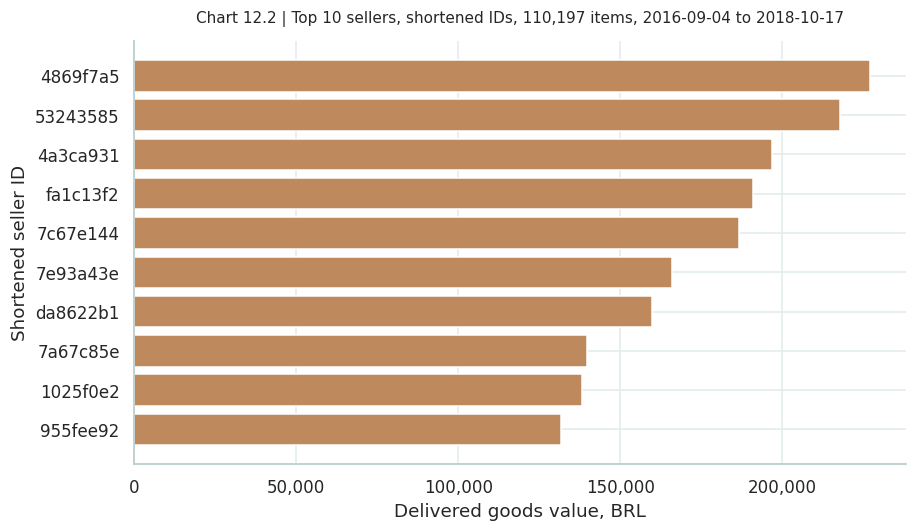

In [33]:
seller_top=seller_sales.sort_values('value_brl',ascending=False).head(10)
top10_seller_share=seller_top.value_brl.sum()/value_delivered*100
seller_top_summary=pd.DataFrame({'value_brl':[seller_top.value_brl.sum()],'share_pct':[top10_seller_share]})
show_table('12.3','Top 10 sellers by delivered goods value',seller_top,
      {'value_brl':'brl'}, {'items':'Items','orders':'Orders','value_brl':'Delivered goods value',
                             'item_rank':'Items rank','value_rank':'Value rank'}, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
show_table('12.4','Top-10 seller share of delivered goods value',seller_top_summary,
      {'value_brl':'brl','share_pct':'pct'},{'value_brl':'Top-10 seller value','share_pct':'Share of total value'}, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
seller_compare_ids=seller_sales.nsmallest(10,'item_rank').index.union(seller_top.index)
seller_comparison=seller_sales.loc[seller_compare_ids].sort_values('item_rank').copy()
seller_comparison['rank_difference']=seller_comparison.value_rank-seller_comparison.item_rank
show_table('12.5','Items-rank vs value-rank comparison for sellers',seller_comparison[['items','value_brl','item_rank','value_rank','rank_difference']],
      {'value_brl':'brl'}, {'items':'Items','orders':'Orders','value_brl':'Delivered goods value',
                             'item_rank':'Items rank','value_rank':'Value rank','rank_difference':'Value-vs-items rank difference'}, sample=f'{len(del_items):,} items', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,5))
ax.barh([str(x)[:8] for x in seller_top.index],seller_top.value_brl,color='#be895c');ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'))
heading(ax,'12.2',f'Top 10 sellers, shortened IDs, {len(del_items):,} items, full period')
axes_labels(ax,'Delivered goods value, BRL','Shortened seller ID');complete()

The seller with the most items does not necessarily have the highest value. Table 12.5 shows each seller's rank on both metrics separately.



### 12.3. Sales and Scores with a Sample Floor

Each review belongs to an order; if an order spans several sellers, the same review is counted for every related seller. Tables 12.6 and 12.7 and Chart 12.3 apply the sample floor. The value threshold in Table 12.6 is built from the third quartile of eligible sellers; roughly a quarter of that group lies above it. The broad screen uses the third quartile of all sellers with delivered items and is separate from the strict list.



,Eligible sellers,Eligible threshold,Strict candidates,Broad threshold,Broad candidates
0,623,"15,259.85 BRL",36,"3,497.88 BRL",129


,Orders,Delivered value,Reviewed orders,Reviews,Review score
seller_id,,,,,
4a3ca9315b744ce9f8e9374361493884,"1,772","196,882.12 BRL","1,753","1,769",3.85
7c67e1448b00f6e969d365cea6b010ab,973,"186,570.05 BRL",967,973,3.50
6560211a19b47992c3666cc44a7e94c0,"1,819","120,702.83 BRL","1,805","1,811",3.98
1ca7077d890b907f89be8c954a02686a,108,"12,474.64 BRL",107,107,2.39


,Delivered items
seller_id,
4a3ca9315b744ce9f8e9374361493884,"1,949"
7c67e1448b00f6e969d365cea6b010ab,"1,355"
6560211a19b47992c3666cc44a7e94c0,"1,996"
1ca7077d890b907f89be8c954a02686a,127


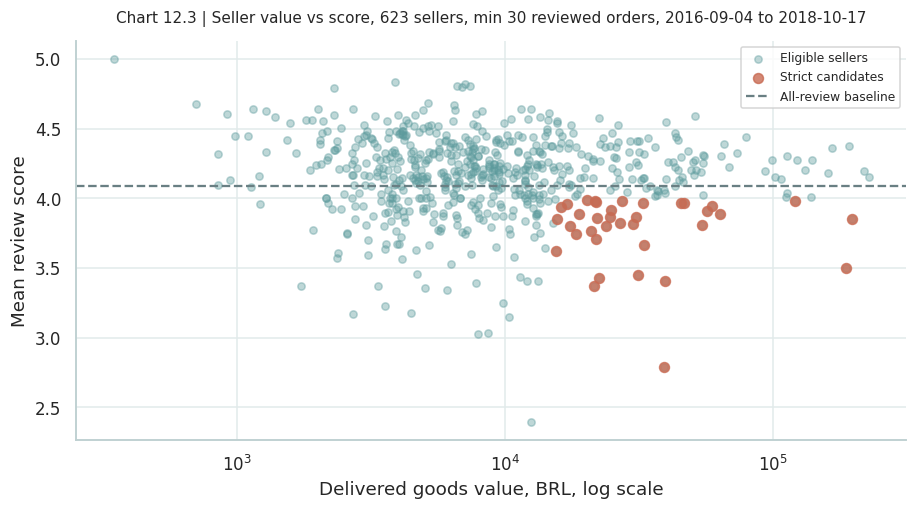

In [34]:
order_seller=del_items[['order_id','seller_id']].drop_duplicates()
seller_review_rows=order_seller.merge(reviews[['order_id','review_score']],on='order_id',how='inner',validate='many_to_many')
seller_review=seller_review_rows.groupby('seller_id').agg(reviewed_orders=('order_id','nunique'),
    review_records=('review_score','size'),mean_score=('review_score','mean'))
seller_metrics=seller_sales.join(seller_review,how='left')
seller_metrics[['reviewed_orders','review_records']]=seller_metrics[['reviewed_orders','review_records']].astype('Int64')
seller_eligible=seller_metrics.loc[seller_metrics.reviewed_orders.ge(MIN_REVIEWS)].copy()
seller_threshold=seller_eligible.value_brl.quantile(.75)
seller_broad_threshold=seller_metrics.value_brl.quantile(.75)
seller_candidates=seller_eligible.loc[(seller_eligible.value_brl.ge(seller_threshold)) &
    (seller_eligible.mean_score.le(review_baseline-SCORE_GAP))].sort_values('value_brl',ascending=False)
seller_broad=seller_eligible.loc[(seller_eligible.value_brl.ge(seller_broad_threshold)) &
    (seller_eligible.mean_score.le(review_baseline-SCORE_GAP))].sort_values(['mean_score','value_brl'])
reference_seller=seller_broad.index[0]
assert reference_seller == '1ca7077d890b907f89be8c954a02686a'
candidate_seller = str(seller_candidates.index[0])
assert candidate_seller == '4a3ca9315b744ce9f8e9374361493884'
assert {reference_seller, candidate_seller}.issubset(set(sellers.seller_id))
seller_screen=pd.DataFrame({'eligible':[len(seller_eligible)],'strict_brl':[seller_threshold],
    'strict_count':[len(seller_candidates)],'broad_brl':[seller_broad_threshold],'broad_count':[len(seller_broad)]})
show_table('12.6',f'Thresholds; at least {MIN_REVIEWS} reviewed orders',seller_screen,
      {'strict_brl':'brl','broad_brl':'brl'},
      {'eligible':'Eligible sellers','strict_brl':'Eligible-group value threshold',
       'strict_count':'Strict candidate count','broad_brl':'All-delivered-sellers value threshold',
       'broad_count':'Broad candidate count'}, sample=f'{len(seller_eligible):,} eligible of {len(seller_metrics):,} sellers', period=ORDER_PERIOD)
seller_selected=pd.concat([seller_candidates.head(3),seller_broad.loc[[reference_seller]]]).loc[
    :,['orders','value_brl','reviewed_orders','review_records','mean_score']]
show_table('12.7',f'Selected sellers, min {MIN_REVIEWS} reviewed orders, and broad-screen sample',seller_selected,
      {'value_brl':'brl','mean_score':'score'},
      {'items':'Items','orders':'Orders','value_brl':'Delivered goods value',
       'reviewed_orders':'Reviewed orders','review_records':'Reviews','mean_score':'Mean review score'}, sample=f'{len(seller_selected):,} selected sellers of {len(seller_eligible):,} eligible', period=ORDER_PERIOD)
show_table('12.8','Delivered items of selected sellers',seller_metrics.loc[seller_selected.index,['items']],
      labels={'items':'Delivered items'}, sample=f'{len(seller_selected):,} selected sellers', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.scatter(seller_eligible.value_brl,seller_eligible.mean_score,s=23,alpha=.4,color='#5d9b9d',label=('Eligible sellers'))
ax.scatter(seller_candidates.value_brl,seller_candidates.mean_score,s=42,alpha=.8,color='#c86b53',label=('Strict candidates'))
ax.axhline(review_baseline,ls='--',color='#697f83',label=('All-review baseline'))
ax.set_xscale('log')
heading(ax,'12.3',f'Seller value vs score, {len(seller_eligible):,} sellers, min {MIN_REVIEWS} reviewed orders')
axes_labels(ax,'Delivered goods value, BRL, log scale','Mean review score')
ax.legend(fontsize=8);complete()

The candidate counts and thresholds are in Table 12.6 and the IDs and details in Table 12.7.

This list is for investigating review texts and the order process; by itself it does not prove seller fault or the cause of dissatisfaction.



# 13. Combined Analyses

In this section, combine information from several tables and examine several variables simultaneously to answer questions that a single table cannot answer.

**Choose at least three of the following analyses.**

## Analysis 1 - Best-selling Categories with Low Satisfaction

Identify categories with high sales value whose mean customer score is below the overall average.

Show sales value and mean score in a relational chart. Identify the categories of interest and explain why this group can matter to the sales and customer-experience teams.

## Analysis 2 - Geography and Delivery Performance

Compute the mean delivery time and the percentage of late orders for different states. Identify states that perform poorly on both indicators.

Present the results so that regions with long delivery times and high late rates can be separated from the rest. Consider each region's order count when interpreting the results.

## Analysis 3 - Product Price and Customer Satisfaction

Compare the prices of sold items with the review score attached to their order. Examine the relationship between the two variables and plot a suitable chart.

Do more expensive products receive higher scores? Can the results be read as "a higher price causes more satisfaction"? Explain your reasoning.

## Analysis 4 - Payment Value and Installments

Examine payment value and installment count for orders. Show the relationship between the two variables and determine whether higher-value payments usually come with more installments.

In your analysis, consider the difference between the number of transactions and the number of unique orders.

## Analysis 5 - Category Sales Changes Over Time

Compute the monthly sales value of different categories. Select a few important categories and compare how their sales changed over time.

Which categories grew or declined notably? Were these changes persistent or visible only in a few specific months?

## Analysis 6 - Seller Performance and Customer Satisfaction

Compute the items sold, sales value and mean customer score for sellers. Identify sellers with high volume and a low score.

Show the results in a relational chart and introduce at least three sellers for closer review. To avoid misleading comparisons, also consider each seller's review count.

---



### 13.1. High-Value Categories with Low Scores

Table 10.7 applies the value condition, the sample size and the gap from the average simultaneously. Table 10.8 compares the selected categories. This screen is a starting point for investigation and does not prove a product defect.



### 13.2. Geography and Delivery

Chart 13.1 compares the mean duration and the late rate of eligible states. The reference lines are the overall means of comparable orders; each state's sample size is in Table 13.1.



,Comparable orders,Late orders,"Mean duration, days","Median duration, days",Late rate
customer_state,,,,,
RJ,"12,350","1,495",15.31,12.04,12.1%
SC,"3,546",291,14.95,13.01,8.2%
BA,"3,256",396,19.34,16.91,12.2%
ES,"1,995",214,15.79,13.64,10.7%
PE,"1,593",153,18.45,15.70,9.6%
CE,"1,279",176,21.27,18.21,13.8%
PA,946,106,23.77,21.08,11.2%
MA,717,125,21.57,19.19,17.4%
MS,701,68,15.62,13.94,9.7%


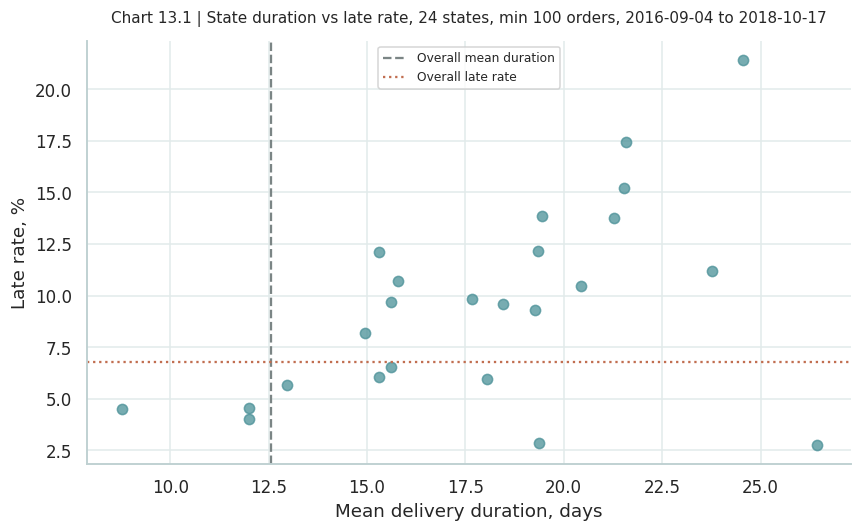

In [35]:
overall_days=delivery.duration_days.mean()
overall_late=delivery.is_late.mean()*100
state_attention=state_eligible.loc[(state_eligible.mean_days.gt(overall_days))&
                                   (state_eligible.late_pct.gt(overall_late))].sort_values('orders',ascending=False)
show_table('13.1',f'States above both averages; at least {MIN_STATE} orders',state_attention,
      {'late_pct':'pct','mean_days':'decimal','median_days':'decimal'},
      {'orders':'Comparable orders','late':'Late orders','mean_days':'Mean duration, days',
       'median_days':'Median duration, days','late_pct':'Late rate'}, sample=f'{len(state_attention):,} selected states of {len(state_eligible):,} eligible', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(state_eligible.mean_days,state_eligible.late_pct,s=45,alpha=.75,color='#4a9097')
ax.axvline(overall_days,ls='--',color='#7b8585',label=('Overall mean duration'))
ax.axhline(overall_late,ls=':',color='#c16e50',label=('Overall late rate'))
heading(ax,'13.1',f'State duration vs late rate, {len(state_eligible):,} states, min {MIN_STATE} orders')
axes_labels(ax,'Mean delivery duration, days','Late rate, %');ax.legend(fontsize=8);complete()

The states above both lines are in Table 13.1. Rate and order count together are useful for prioritizing routes; this comparison does not prove the cause of the differences.



### 13.3. Item Price and Order Score

Each delivered item is attached to the mean score of its order's reviews; here the score unit is the "order", separate from the main "review" basis in Table 10.1. Chart 13.2 and Table 13.2 show the rank association.



,Items,Rank correlation
0,"109,370",0.01


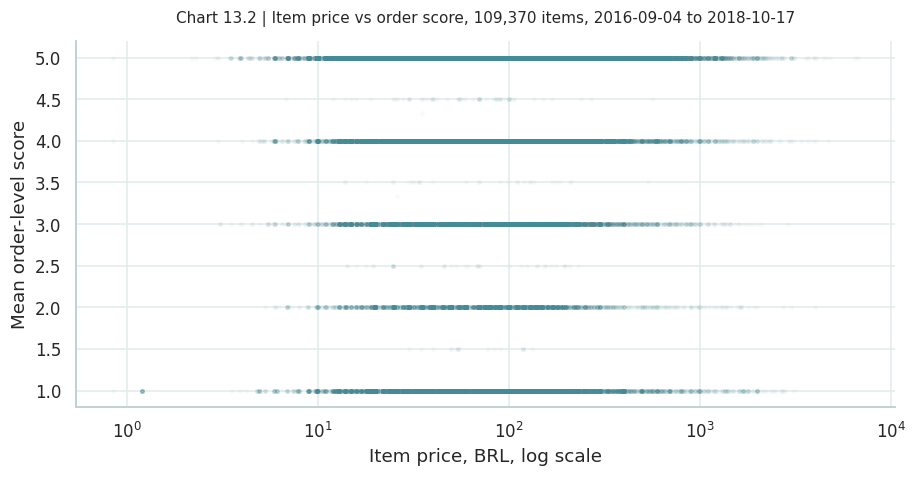

In [36]:
items_scored=del_items.merge(review_order,on='order_id',how='inner',validate='many_to_one').dropna(subset=['price','order_mean_score'])
price_rho=items_scored.price.rank().corr(items_scored.order_mean_score.rank())
price_relation=pd.DataFrame({'items':[len(items_scored)],'rank_correlation':[price_rho]})
show_table('13.2','Item price vs mean order-level score',price_relation,
      {'rank_correlation':'decimal'},{'items':'Items','rank_correlation':'Rank correlation'}, sample=f'{len(items_scored):,} items', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.5,4.5))
price_plot=items_scored.loc[items_scored.price.gt(0)]
ax.scatter(price_plot.price,price_plot.order_mean_score,s=5,alpha=.025,color='#438b96')
ax.set_xscale('log')
heading(ax,'13.2',f'Item price vs order score, {len(price_plot):,} items, full period')
axes_labels(ax,'Item price, BRL, log scale','Mean order-level score');complete()

The correlation value and the sample are in Table 13.2.

A price-score correlation by itself cannot prove that a higher price changes satisfaction.



### 13.4. Payment Value and Installments at Order Level

The transactions of each order are summed and the order's maximum installment count is taken; multi-transaction orders are counted separately. Table 13.3 has a different unit than the transaction-level analysis in Table 8.3.



,Orders with payment,Multi-txn,Rank correlation
0,"99,440","2,961",0.38


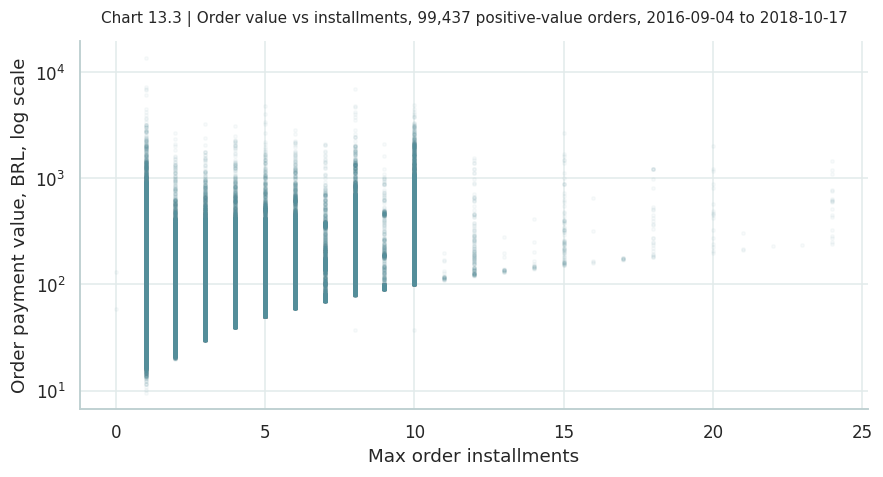

In [37]:
order_pay=payments.groupby('order_id').agg(total_brl=('payment_value','sum'),
    max_installments=('payment_installments','max'),transactions=('payment_value','size'))
order_pay_rho=order_pay.total_brl.rank().corr(order_pay.max_installments.rank())
multi_payment_orders=int(order_pay.transactions.gt(1).sum())
order_pay_summary=pd.DataFrame({'orders':[len(order_pay)],'multi_orders':[multi_payment_orders],
    'rank_correlation':[order_pay_rho]})
show_table('13.3','Order-level value and installments',order_pay_summary,{'rank_correlation':'decimal'},
      {'orders':'Orders with payment','multi_orders':'Multi-transaction orders','rank_correlation':'Rank correlation'}, sample=f'{len(order_pay):,} orders', period=ORDER_PERIOD)
fig,ax=plt.subplots(figsize=(8.2,4.5))
order_pay_plot=order_pay.loc[order_pay.total_brl.gt(0)]
ax.scatter(order_pay_plot.max_installments,order_pay_plot.total_brl,s=5,alpha=.04,color='#548e9a')
ax.set_yscale('log')
heading(ax,'13.3',f'Order value vs installments, {len(order_pay_plot):,} positive-value orders, full period')
axes_labels(ax,'Max order installments','Order payment value, BRL, log scale');complete()

The coefficient and the multi-transaction order count are in Table 13.3.

This comparison helps design payment experiments, but it does not show the causal effect of offering installments.



### 13.5. Category Value Change Over Time

Chart 13.4 compares the top five categories by delivered goods value within the stated window. Table 13.4 shows the same-month totals and Table 13.5 the percentage change for the same keys.


Table 13.4 | Category value in same months | 33,196 items in same months | 2017-01 to 2018-08
                                          Items Delivered value
category              period                                   
health_beauty         2017-01 to 2017-08  1,822  243,521.70 BRL
                      2018-01 to 2018-08  5,841  755,724.50 BRL
watches_gifts         2017-01 to 2017-08    839  201,137.86 BRL
                      2018-01 to 2018-08  3,628  687,855.20 BRL
bed_bath_table        2017-01 to 2017-08  2,558  254,444.82 BRL
                      2018-01 to 2018-08  5,810  532,358.85 BRL
sports_leisure        2017-01 to 2017-08  1,982  216,724.33 BRL
                      2018-01 to 2018-08  4,436  517,166.26 BRL
computers_accessories 2017-01 to 2017-08  1,658  214,631.27 BRL
                      2018-01 to 2018-08  4,622  496,269.30 BRL

period,2017-01 to 2017-08,2018-01 to 2018-08,Value change
category,,,
bed_bath_table,"254,444.82 BRL","532,358.85 BRL",109.2%
computers_accessories,"214,631.27 BRL","496,269.30 BRL",131.2%
health_beauty,"243,521.70 BRL","755,724.50 BRL",210.3%
sports_leisure,"216,724.33 BRL","517,166.26 BRL",138.6%
watches_gifts,"201,137.86 BRL","687,855.20 BRL",242.0%


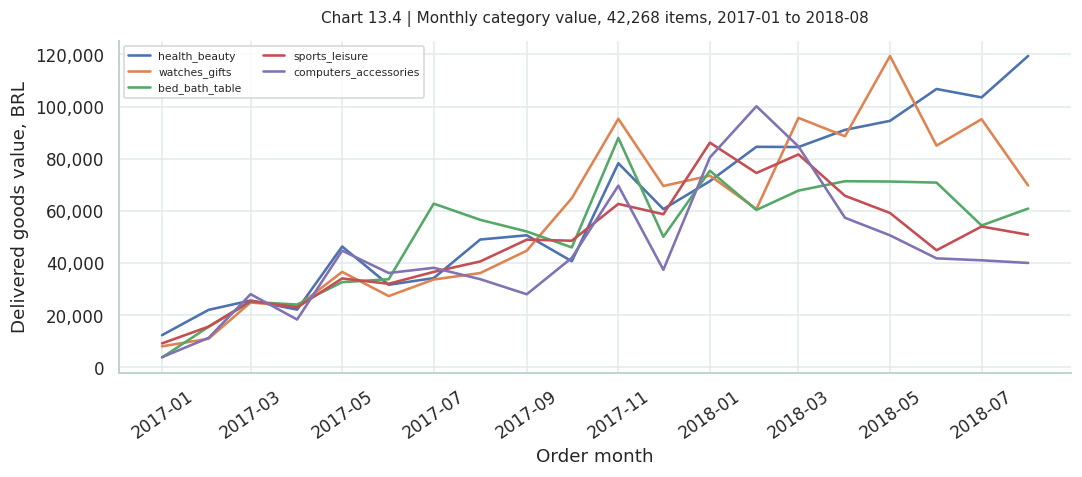

In [38]:
top5_categories=top_value_categories.head(5).index.tolist()
category_month=del_items.loc[del_items.category.isin(top5_categories)&
    del_items.order_purchase_timestamp.ge(START)&del_items.order_purchase_timestamp.lt(END)].copy()
category_monthly=category_month.groupby(['purchase_month','category']).price.sum().unstack('category').reindex(columns=top5_categories,fill_value=0)
category_period=[]
for category in top5_categories:
    for year in (FIRST_YEAR,LAST_YEAR):
        values=category_month.loc[category_month.category.eq(category)&
                category_month.order_purchase_timestamp.ge(f'{year}-01-01')&
                category_month.order_purchase_timestamp.lt(f'{year}-09-01')]
        category_period.append({'category':category,'period':f'{year}-01 to {year}-08',
                                'items':len(values),'value_brl':values.price.sum()})
category_year=pd.DataFrame(category_period).set_index(['category','period'])
show_table('13.4','Category value in same months',category_year,{'value_brl':'brl'},
      {'items':'Items','value_brl':'Delivered goods value'}, sample=f'{int(category_year["items"].sum()):,} items in same months', period=TREND_PERIOD)
category_year_pivot=category_year.value_brl.unstack('period')
category_year_pivot['change_pct']=(category_year_pivot['2018-01 to 2018-08'].div(
    category_year_pivot['2017-01 to 2017-08'])-1)*100
show_table('13.5','Category value change across same-month periods',category_year_pivot,
      {'2017-01 to 2017-08':'brl','2018-01 to 2018-08':'brl','change_pct':'pct'},
      {'change_pct':'Value change'}, sample=f'{int(category_year["items"].sum()):,} items in same months', period=TREND_PERIOD)
fig,ax=plt.subplots(figsize=(10,4.5))
for name in top5_categories:
    ax.plot(category_monthly.index.to_timestamp(),category_monthly[name],label=name,linewidth=1.7)
heading(ax,'13.4',f'Monthly category value, {len(category_month):,} items',TREND_PERIOD)
axes_labels(ax,'Order month','Delivered goods value, BRL')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'));ax.legend(fontsize=7,ncol=2);plt.xticks(rotation=35);complete()

Period gaps and monthly fluctuation per category can be read from the table and the chart.

A short-term change does not necessarily prove a persistent trend or a change in profit.



### 13.6. Sellers and Satisfaction

Table 12.7 introduces the candidate sellers with full IDs and reviewed-order counts, and Table 12.8 shows their delivered items. A broad-screen sample may fall below the strict value threshold. A review text belongs to the whole order and is no substitute for a formal case file.



# 14. Final Report for Management

Imagine the analysis is finished and the results must be presented to Olist's managers.

Managers are not interested in Python code; they want to know what the data says about the state of the business and which actions can be proposed on that basis.

## 14.1. Business Status Summary

In a few paragraphs, explain the most important results about:

- the order trend
- products
- customers
- delivery performance
- customer satisfaction

## 14.2. Five Key Findings

Choose the five most important findings of the project. For each finding:

1. State the result in plain language.
2. Provide the number or indicator that supports the result.
3. Add the chart that best shows the evidence.
4. Explain why the finding matters to the business.

## 14.3. Three Recommendations for Management

Provide three practical recommendations to improve business performance.

For each recommendation explain:

1. What is the problem you intend to address?
2. Which finding from your analysis supports this recommendation?
3. What change do you expect this action to create?
4. Which indicator can be monitored in the future to evaluate the outcome?

**Note:** recommendations must be based on analytical evidence; avoid advice the available data does not support.

---



### Executive Summary

The answer to the four management questions is in the final wrap-up. The five findings below place the same indicators next to their comparisons and their management use.

**Finding 1 - Order and value trend:** Tables 5.3 and 7.7 compare the same-month periods and Chart 5.2 shows the whole continuous window. Volume growth matters for capacity planning; its continuation is not guaranteed.

**Finding 2 - Customer concentration:** Table 6.2 and Chart 6.1 show the customer spread. Concentration in the leading states makes regional service planning important.

**Finding 3 - Late rate:** Table 9.6 and Chart 9.3 show the late-rate increase. Each period's denominator is recorded in the table; monitoring delivery routes is a priority.

**Finding 4 - Score and delivery:** Table 11.2 compares the review scores of early and on-time orders with late orders. Table 11.3 splits delay severity and Chart 11.1 shows the groups. This relationship does not prove the cause of the score difference.

**Finding 5 - Category and seller:** Table 10.8 shows the selected category's gap from the review baseline. Table 12.7 introduces candidate sellers with a sample floor and Chart 7.2 shows the category value ranking. These are starting points for investigating the order experience.



In [39]:

print(f'Orders in same-month periods | {orders_2017:,} -> {orders_2018:,} | {order_growth:.1f}%')
print(f'Unique customers in SP / RJ | {state_summary.loc["SP","share_pct"]:.1f}% / {state_summary.loc["RJ","share_pct"]:.1f}%')
print(f'Late rate in same-month periods | {delivery_compare.iloc[0].late_pct:.1f}% -> {delivery_compare.iloc[1].late_pct:.1f}%')
print(f'Early & on-time / late review scores | {score_by_late.loc[False,"mean_score"]:.2f} / {score_by_late.loc[True,"mean_score"]:.2f}')
print(f'office_furniture score / all-review baseline | {category_metrics.loc["office_furniture","mean_score"]:.2f} / {review_baseline:.2f}')


Orders in same-month periods | 22,968 -> 53,991 | 135.1%
Unique customers in SP / RJ | 41.9% / 12.9%
Late rate in same-month periods | 3.5% -> 7.7%
Early & on-time / late review scores | 4.29 / 2.27
office_furniture score / all-review baseline | 3.64 / 4.09


### Three Management Actions

**Delivery routes:** the rising late rate and the state differences in Tables 9.4 and 9.6 define the problem. A pilot on a selected route with a comparison group, monitoring order count, late rate and duration and actual delivery time.

**Category and seller:** the lower scores of the eligible category and sellers in Tables 10.8 and 12.7 are the evidence. Review-text investigation and an improvement pilot next to a comparison group, monitoring review count, mean score and the share of low-score reviews.

**Customer return:** the second-order rate in Table 6.5 defines the problem. A limited retention pilot next to a comparison group, monitoring the second-order rate, group size and cost.

### Strengths and Limitations

The share of early deliveries and of high-score reviews are strengths; the values and denominators are in Tables 9.2 and 10.1.

- Delivered goods value excludes freight, costs and profit.
- Refund information and the reason for every payment difference are unavailable.
- Some categories, sellers and states are too small for comparison.
- Coverage of the first and last months of the data is uncertain.
- Not every order has a review and each review belongs to the whole order.
- The first order recorded in the data is not necessarily the real first purchase.
- A statistical relationship by itself does not prove cause or a definite outcome.



# 15. Chart Requirements and Presenting Results

This project does not require a chart for every question. A chart is needed when it helps understand a distribution, compare groups, examine a time trend or discover a relationship between variables.

Wherever a question asks to examine a trend, compare groups or identify a relationship, use a chart that clearly shows the answer to that question.

## Requirements for Every Chart

- Have a clear title.
- Axes have proper labels.
- Where needed, the unit of measurement is stated.
- The chart type fits the analysis goal and the data.
- After the chart, explain in a few sentences which pattern is visible.
- State the business meaning of the observed pattern.

**Final goal:** plotting is not the point; charts must be used to answer business questions and extract insight.

---



### Answers to the Four Management Questions

**Business status:** order count and delivered goods value rise across the same-month periods; Tables 5.3 and 7.7 show the comparison.

**Customer behavior:** state concentration and the second-order rate under an equal window are in Tables 6.2 and 6.5.

**Strengths:** the share of early deliveries and the share of high scores are in Tables 9.2 and 10.1.

**Areas to investigate:** the rising late rate and the review-score gap of late orders are recorded in Tables 9.6 and 11.2.



# 16. Final Delivery

At the end, deliver the following files.

## 16.1. Jupyter Notebook File

A `.ipynb` file containing:

- analysis code
- required outputs
- charts
- analytical notes
- results and business interpretations

## 16.2. Management Report PDF

Prepare a PDF report that presents the project's main findings and recommendations in a compact form without programming code.

## 16.3. Final Project Review

Before delivery:

- Run the notebook from the start.
- Make sure cells execute in order.
- There are no runtime errors.
- The required charts and results are displayed.
- Notes and conclusions match the analysis outputs.
- The management report file is complete and readable.

## 16.4. Packaging the Files

All essential project files must be inside a single ZIP file.

**Do not send the files separately.**

---

<div style="text-align: left;">

**End of project description**

Data analysis, insight extraction and evidence-based recommendations

</div>



### Computation Control

Table 16.1 shows checks on sums, ranges, keys, delivery groups and seller identifiers.



In [40]:

expected_categories = {'office_furniture','bed_bath_table','health_beauty','computers_accessories'}
original_keys = {'pc_gamer','portateis_cozinha_e_preparadores_de_alimentos'}
checks = {
 'Order row count preserved': len(orders)==len(raw['orders']),
 'Item row count preserved': len(all_items)==len(raw['items']),
 'Review row count preserved': len(reviews)==len(raw['reviews']),
 'Geo duplicates consistent': len(geo_unique)+int(geo.duplicated().sum())==len(geo),
 'Value base is delivered-only': del_items.order_status.eq('delivered').all(),
 'Category value sums consistent': np.isclose(category_sales.value_brl.sum(),value_delivered),
 'Seller value sums consistent': np.isclose(seller_sales.value_brl.sum(),value_delivered),
 'Score base is all reviews': score_counts.reviews.sum()==len(reviews),
 'Order window matches constants': core_monthly.index.min()==START.to_period('M') and core_monthly.index.max()==(END-pd.Timedelta(days=1)).to_period('M'),
 'Delivery window matches constants': monthly_delivery.index.min()>=START.to_period('M') and monthly_delivery.index.max()<END.to_period('M'),
 'Review window matches constants': monthly_reviews.index.min()>=START.to_period('M') and monthly_reviews.index.max()<END.to_period('M'),
 'Period split consistent': orders_2017+orders_2018+mid_orders==int(core_monthly.sum()),
 'Delivery groups consistent': ((delivery.delivery_group.eq('late'))==delivery.delay_days.gt(0)).all() and ((delivery.delivery_group.eq('on_time'))==delivery.delay_days.eq(0)).all() and ((delivery.delivery_group.eq('early'))==delivery.delay_days.lt(0)).all(),
 'Category min sample respected': category_eligible.review_records.ge(MIN_REVIEWS).all(),
 'Seller min sample respected': seller_eligible.reviewed_orders.ge(MIN_REVIEWS).all(),
 'State min sample respected': state_eligible.orders.ge(MIN_STATE).all(),
 'Category keys exist in data': expected_categories.issubset(set(category_sales.index)),
 'Untranslated keys preserved': original_keys.issubset(set(untranslated_categories.index)),
 'not_defined payment type present': 'not_defined' in set(payments.payment_type),
 'Reference seller ID exists': reference_seller=='1ca7077d890b907f89be8c954a02686a' and reference_seller in set(sellers.seller_id),
 'Candidate seller ID exists': candidate_seller=='4a3ca9315b744ce9f8e9374361493884' and candidate_seller in set(sellers.seller_id),
 'Seller table IDs exist in data': set(seller_selected.index).issubset(set(sellers.seller_id)) and set(seller_top.index).issubset(set(sellers.seller_id)),
 'Second-order window complete': (cohorts.first_order+pd.Timedelta(days=WINDOW_DAYS)<END).all(),
 'Payment difference parts equal': np.isclose(payment_parts.difference_brl.sum(),payment_difference),
 'Payment vs delivered gap correct': np.isclose(payment_total-value_delivered,recon_total.delivered_gap_brl.iloc[0]),
 'Payment-type allocation consistent': np.isclose(recon_type.allocated_brl.sum(),payment_difference),
 'Score column order correct': list(group_reviews.columns)==['review_records','reviewed_orders','mean_score'] and list(score_by_late.columns)==['review_records','reviewed_orders','mean_score','gap_score'],
 'Seller rank difference correct': seller_comparison.rank_difference.eq(seller_comparison.value_rank-seller_comparison.item_rank).all(),
 'Delay-band score consistent': np.isclose(severity.loc['4-7','mean_score'],late_reviews.loc[late_reviews.delay_days.between(4,7),'review_score'].mean()),
}
assert all(checks.values()), [name for name, passed in checks.items() if not passed]
show_table('16.1','Checks on sums, keys and windows',pd.Series(checks,name='passed').to_frame(),labels={'passed':'OK'}, sample=f'{len(checks):,} checks', period=ORDER_PERIOD)
report_payload={
 'date_min':str(orders.order_purchase_timestamp.min().date()),'date_max':str(orders.order_purchase_timestamp.max().date()),
 'orders_total':int(len(orders)),'orders_delivered':int(len(delivered_orders)),
 'orders_2017':orders_2017,'orders_2018':orders_2018,'order_growth':float(order_growth),
 'delivered_value':float(value_delivered),'all_status_value':float(value_all),
 'delivered_value_2017':float(delivered_period_values[0]),'delivered_value_2018':float(delivered_period_values[1]),
 'delivered_value_growth':float(delivered_growth),'delivered_items':int(len(del_items)),
 'customers':unique_customers,'state_sp_n':int(state_summary.loc['SP','customers']),
 'state_sp_pct':float(state_summary.loc['SP','share_pct']),
 'state_rj_n':int(state_summary.loc['RJ','customers']),'state_rj_pct':float(state_summary.loc['RJ','share_pct']),
 'top5_state_pct':float(top5_state_share),'single_customers':single_customers,
 'single_pct':float(single_customers/unique_customers*100),'cohort_customers':int(len(cohorts)),
 'cohort_repeat':int(cohorts.repeat_90d.sum()),'cohort_pct':float(repeat_90d_pct),
 'category_top5_pct':float(top5_category_share),'category_reference_threshold':float(category_value_threshold),
 'office_value':float(category_metrics.loc['office_furniture','value_brl']),
 'office_score':float(category_metrics.loc['office_furniture','mean_score']),
 'office_reviews':int(category_metrics.loc['office_furniture','review_records']),
 'office_reviewed_orders':int(category_metrics.loc['office_furniture','reviewed_orders']),
 'bed_value':float(category_metrics.loc['bed_bath_table','value_brl']),
 'bed_score':float(category_metrics.loc['bed_bath_table','mean_score']),
 'bed_reviews':int(category_metrics.loc['bed_bath_table','review_records']),
 'bed_gap':float(category_metrics.loc['bed_bath_table','score_gap']),
 'bed_candidate':bool('bed_bath_table' in category_candidates.index),
 'review_baseline':float(review_baseline),'reviews':int(len(reviews)),'score_max':int(reviews.review_score.max()),
 'good_pct':float(good_pct),'low_pct':float(low_pct),
 'review2017':float(review_compare.loc['2017-01 to 2017-08','mean_score']),
 'review2018':float(review_compare.loc['2018-01 to 2018-08','mean_score']),
 'review_march':float(review_compare.loc['2018-03','mean_score']),
 'review_march_n':int(review_compare.loc['2018-03','reviews']),
 'eligible_delivery':int(len(delivery)),'late_count':late_count,'late_pct':float(late_pct),
 'early_count':int(delivery_groups.loc['early','orders']),
 'early_pct':float(delivery_groups.loc['early','share_pct']),
 'on_time_count':int(delivery_groups.loc['on_time','orders']),
 'on_time_pct':float(delivery_groups.loc['on_time','share_pct']),
 'late_days_mean':float(late_mean),'late_over7':late_over7,
 'delay2017_n':int(delivery_compare.loc['2017-01 to 2017-08','orders']),
 'delay2017_late':int(delivery_compare.loc['2017-01 to 2017-08','late']),
 'delay2017_pct':float(delivery_compare.loc['2017-01 to 2017-08','late_pct']),
 'delay2018_n':int(delivery_compare.loc['2018-01 to 2018-08','orders']),
 'delay2018_late':int(delivery_compare.loc['2018-01 to 2018-08','late']),
 'delay2018_pct':float(delivery_compare.loc['2018-01 to 2018-08','late_pct']),
 'delay_change_pp':float(delay_change_pp),'march_delay_n':int(delivery_compare.loc['2018-03','orders']),
 'march_delay_pct':float(delivery_compare.loc['2018-03','late_pct']),
 'rj_delivery_n':int(state_eligible.loc['RJ','orders']),'rj_late_n':int(state_eligible.loc['RJ','late']),
 'rj_late_pct':float(state_eligible.loc['RJ','late_pct']),
 'al_delivery_n':int(state_eligible.loc['AL','orders']),'al_late_n':int(state_eligible.loc['AL','late']),
 'al_late_pct':float(state_eligible.loc['AL','late_pct']),
 'on_time_score':float(score_by_late.loc[False,'mean_score']),
 'on_time_reviews':int(score_by_late.loc[False,'review_records']),
 'on_time_orders':int(score_by_late.loc[False,'reviewed_orders']),
 'late_score':float(score_by_late.loc[True,'mean_score']),
 'late_reviews':int(score_by_late.loc[True,'review_records']),
 'late_review_orders':int(score_by_late.loc[True,'reviewed_orders']),
 'severity':{str(k):{'score':float(row.mean_score),'reviews':int(row.review_records),
                      'orders':int(row.reviewed_orders)} for k,row in severity.iterrows()},
 'payment_total':float(payment_total),'payment_difference':float(payment_difference),
 'payment_unavailable_diff':float(recon_status.loc['unavailable','difference_brl']),
 'payment_canceled_diff':float(recon_status.loc['canceled','difference_brl']),
 'payment_unavailable_no_item_brl':float(recon_status.loc['unavailable','paid_without_item_brl']),
 'payment_canceled_no_item_brl':float(recon_status.loc['canceled','paid_without_item_brl']),
 'unavailable_no_item':int(recon_status.loc['unavailable','no_item_orders']),
 'payment_card_pct':float(payment_summary.loc['credit_card','share_pct']),
 'payment_transactions':int(len(payments)),
 'reference_seller':reference_seller,'reference_seller_value':float(seller_metrics.loc[reference_seller,'value_brl']),
 'reference_seller_score':float(seller_metrics.loc[reference_seller,'mean_score']),
 'reference_seller_orders':int(seller_metrics.loc[reference_seller,'reviewed_orders']),
 'seller_candidate':candidate_seller,
 'seller_candidate_score':float(seller_candidates.iloc[0].mean_score),
 'seller_candidate_value':float(seller_candidates.iloc[0].value_brl),
 'seller_candidate_orders':int(seller_candidates.iloc[0].reviewed_orders),
 'seller_selected_count':int(len(seller_selected)),
 'trend_start':str(START.date()),'trend_end':str((END-pd.Timedelta(days=1)).date()),
 'delay_band_4_start':int(late_reviews.loc[late_reviews.delay_days.between(4,7),'delay_days'].min()),
 'delay_band_4_end':int(late_reviews.loc[late_reviews.delay_days.between(4,7),'delay_days'].max()),
 'continuous_orders':int(core_monthly.sum()),'shared_orders':int(orders_2017+orders_2018),
 'middle_orders':int(mid_orders),'continuous_months':int(len(core_monthly)),
 'core_delivery_count':int(len(core_delivery)), 'core_review_count':int(len(core_reviews)),
 'outside_review_count':int(len(reviews)-len(core_reviews)),
 'review_start':str(reviews.review_creation_date.min().date()),'review_end':str(reviews.review_creation_date.max().date()),
 'payment_delivered_gap':float(payment_total-value_delivered), 'payment_remainder':float(payment_residual),
 'delivered_missing_date':int(delivered_orders.order_delivered_customer_date.isna().sum()),
 'other_status_delivery_date':int((~orders.order_status.eq('delivered')&orders.order_delivered_customer_date.notna()).sum()),
 'not_defined_count':int(payments.payment_type.eq('not_defined').sum()),
 'min_reviews':MIN_REVIEWS,'min_state':MIN_STATE,'score_gap_threshold':SCORE_GAP,
}

,OK
Order row count preserved,True
Item row count preserved,True
Review row count preserved,True
Geo duplicates consistent,True
Value base is delivered-only,True
Category value sums consistent,True
Seller value sums consistent,True
Score base is all reviews,True
Order window matches constants,True
Delivery window matches constants,True
